In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import interpolate
from scipy.stats import gaussian_kde
import glob
import pickle
import matplotlib
import os
from numpy import correlate

from scipy.signal import coherence
from scipy.fft import fft, fftfreq


matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [5]:
Fs = 3e4
L = 600  # still 600 — used to trim upsampled to match p_spike
chunk_size = 210  # 7ms bins
out_path = './dataFolder/6_NaturalBehavior/Clipped_test/v3/CrossCor/'
os.makedirs(out_path, exist_ok=True)

out_fig = './dataFolder/Figures/4_NaturalBehavior/clipped/v3/CrossCor/'
os.makedirs(out_fig, exist_ok=True)

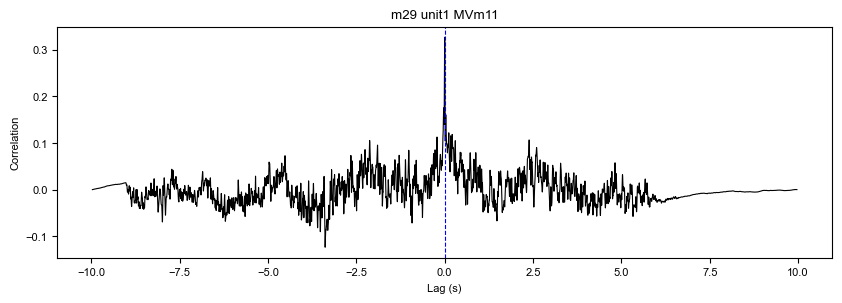

m29 unit1 MVm11: peak=0.326 at lag=0.0005s | at_zero=0.326


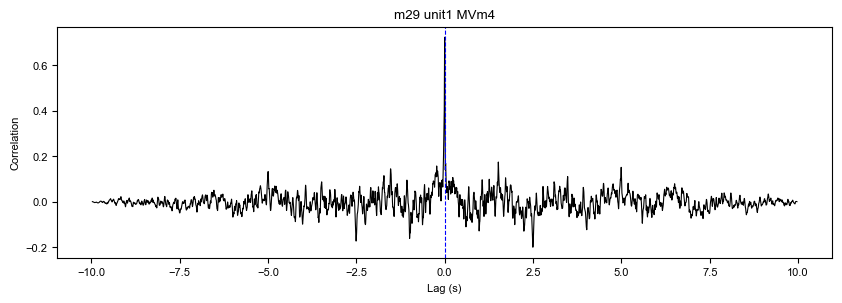

m29 unit1 MVm4: peak=0.724 at lag=0.0001s | at_zero=0.724


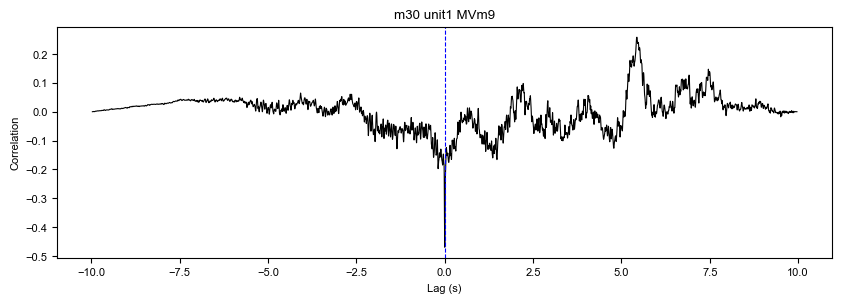

m30 unit1 MVm9: peak=-0.469 at lag=0.0023s | at_zero=-0.457


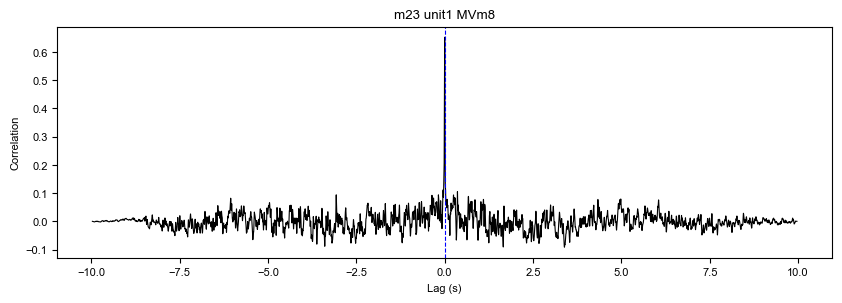

m23 unit1 MVm8: peak=0.653 at lag=0.0005s | at_zero=0.652


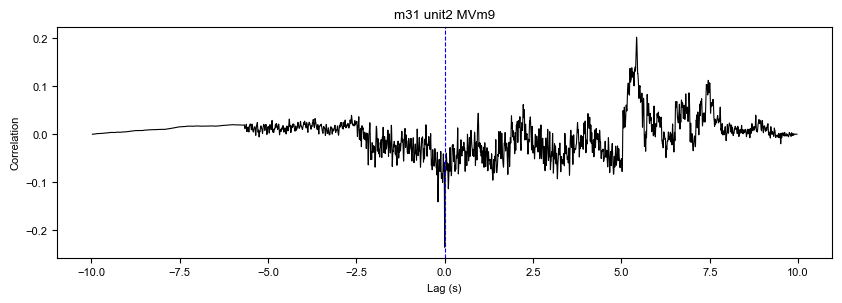

m31 unit2 MVm9: peak=-0.235 at lag=0.0018s | at_zero=-0.229


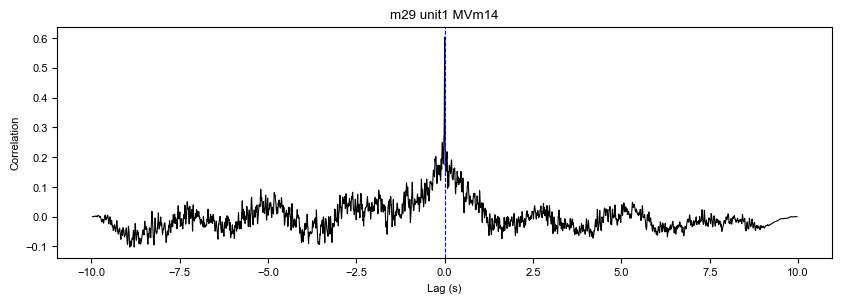

m29 unit1 MVm14: peak=0.603 at lag=0.0003s | at_zero=0.602


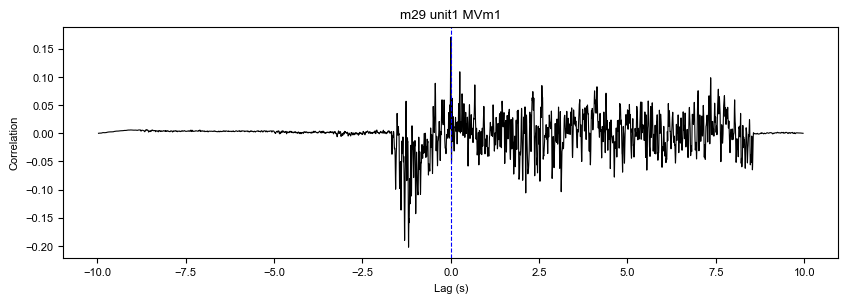

m29 unit1 MVm1: peak=-0.202 at lag=-1.1951s | at_zero=0.170


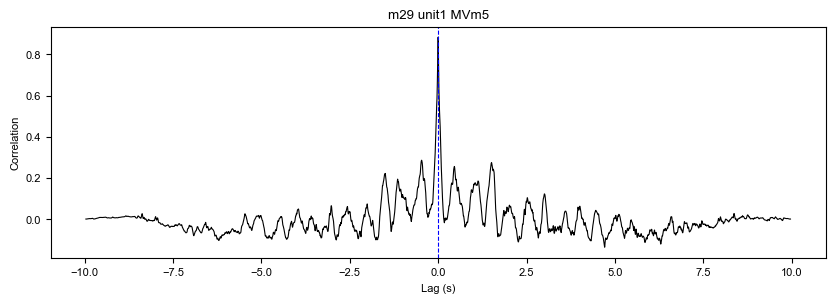

m29 unit1 MVm5: peak=0.883 at lag=-0.0005s | at_zero=0.883


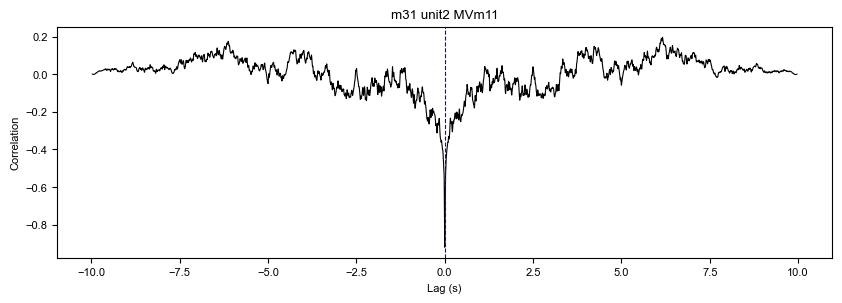

m31 unit2 MVm11: peak=-0.921 at lag=0.0018s | at_zero=-0.910


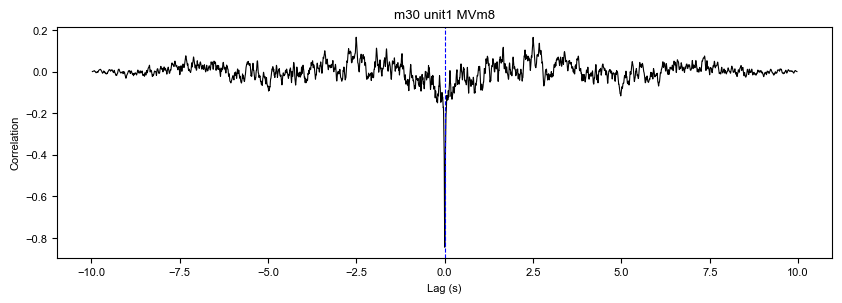

m30 unit1 MVm8: peak=-0.845 at lag=0.0025s | at_zero=-0.821


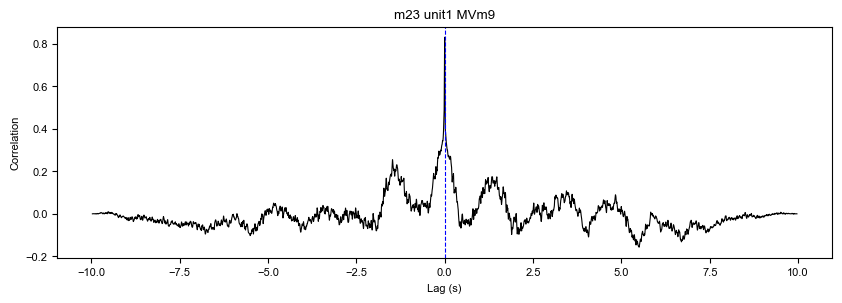

m23 unit1 MVm9: peak=0.830 at lag=0.0004s | at_zero=0.829


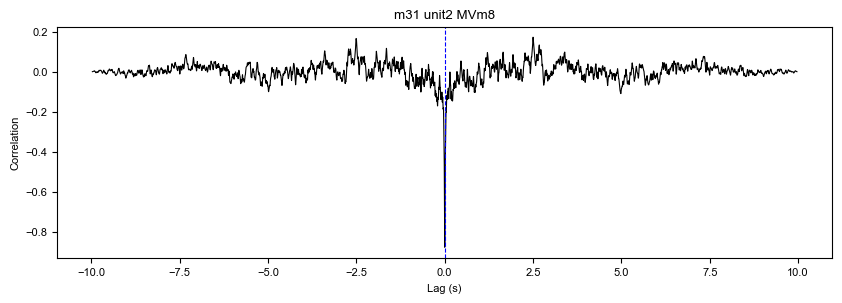

m31 unit2 MVm8: peak=-0.878 at lag=0.0019s | at_zero=-0.863


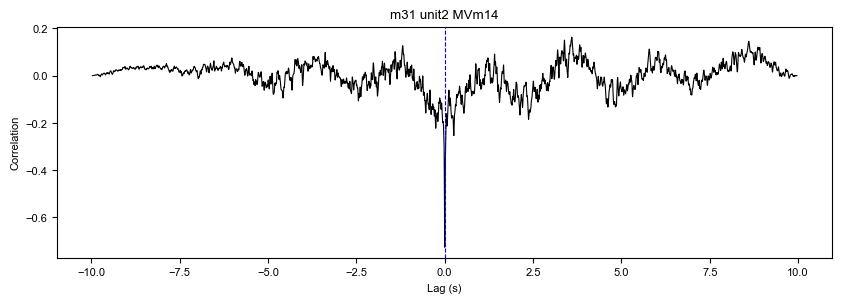

m31 unit2 MVm14: peak=-0.726 at lag=0.0018s | at_zero=-0.715


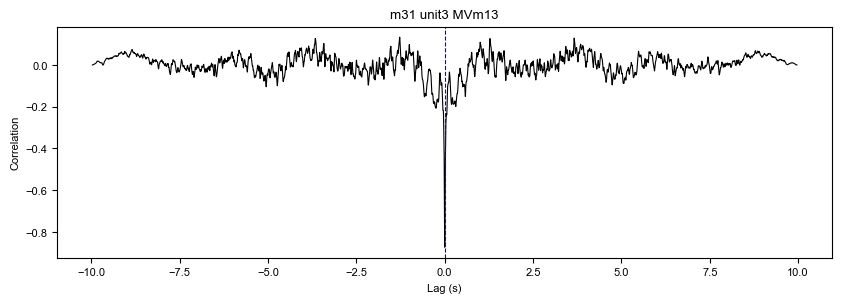

m31 unit3 MVm13: peak=-0.873 at lag=0.0013s | at_zero=-0.867


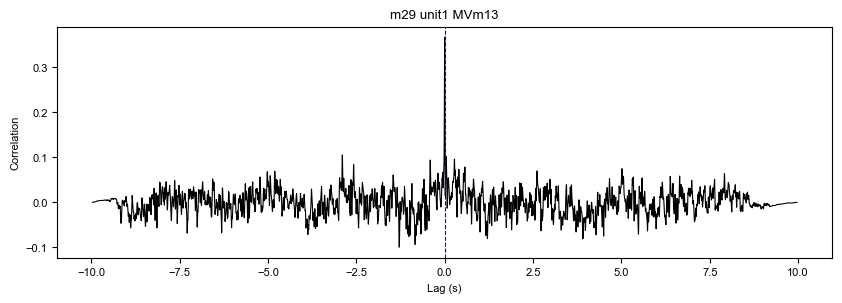

m29 unit1 MVm13: peak=0.367 at lag=0.0000s | at_zero=0.367


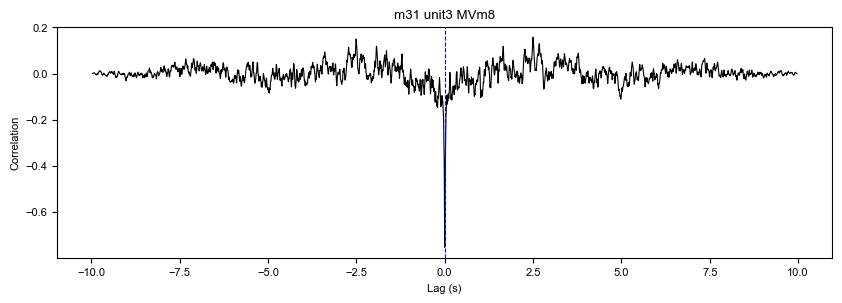

m31 unit3 MVm8: peak=-0.753 at lag=0.0016s | at_zero=-0.745


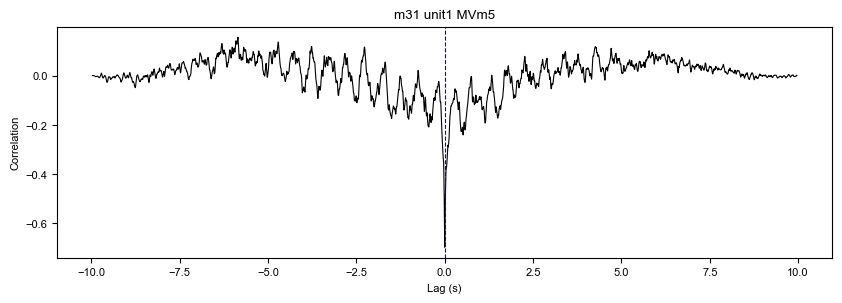

m31 unit1 MVm5: peak=-0.696 at lag=0.0014s | at_zero=-0.693


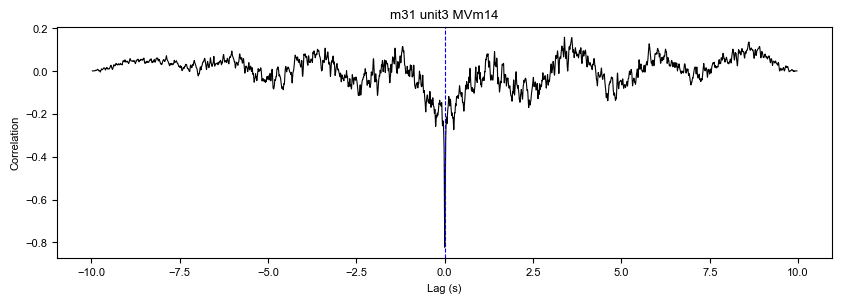

m31 unit3 MVm14: peak=-0.823 at lag=0.0014s | at_zero=-0.815


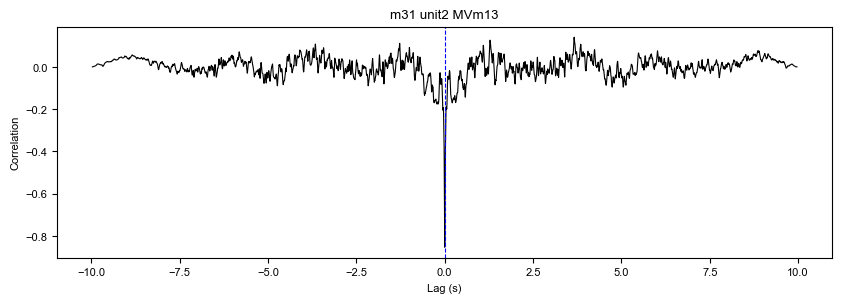

m31 unit2 MVm13: peak=-0.853 at lag=0.0018s | at_zero=-0.841


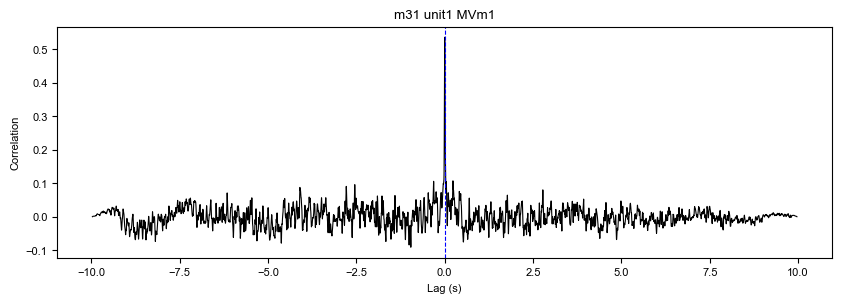

m31 unit1 MVm1: peak=0.535 at lag=0.0012s | at_zero=0.531


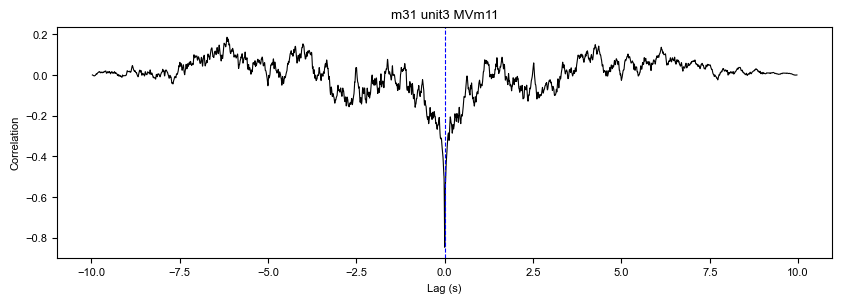

m31 unit3 MVm11: peak=-0.847 at lag=0.0015s | at_zero=-0.841


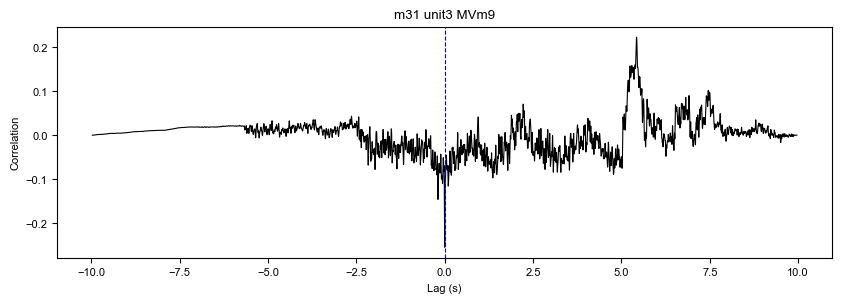

m31 unit3 MVm9: peak=-0.255 at lag=0.0008s | at_zero=-0.253


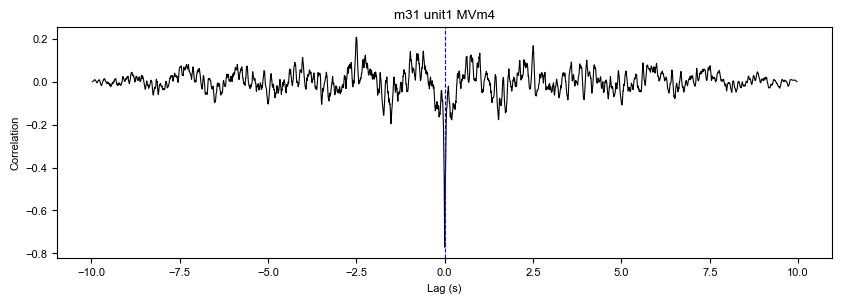

m31 unit1 MVm4: peak=-0.772 at lag=0.0012s | at_zero=-0.767


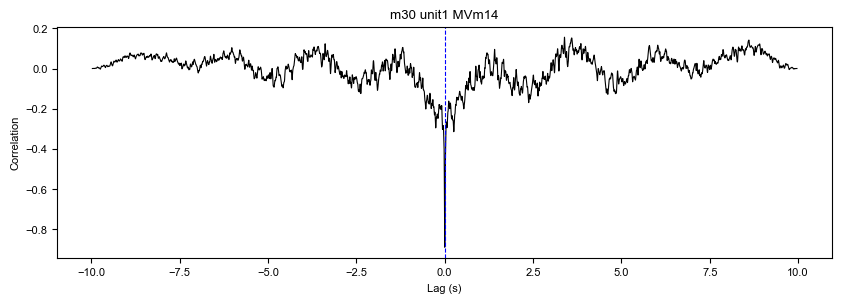

m30 unit1 MVm14: peak=-0.890 at lag=0.0025s | at_zero=-0.868


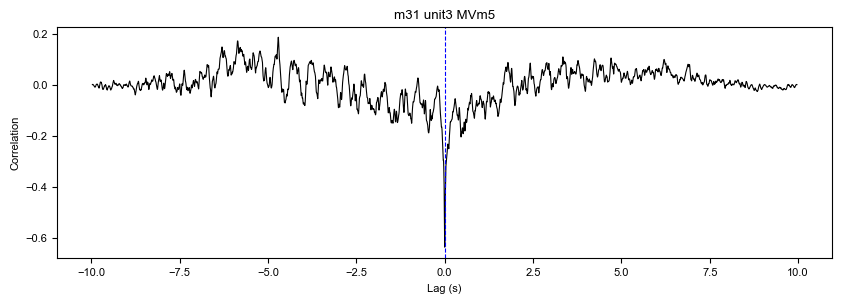

m31 unit3 MVm5: peak=-0.637 at lag=0.0014s | at_zero=-0.634


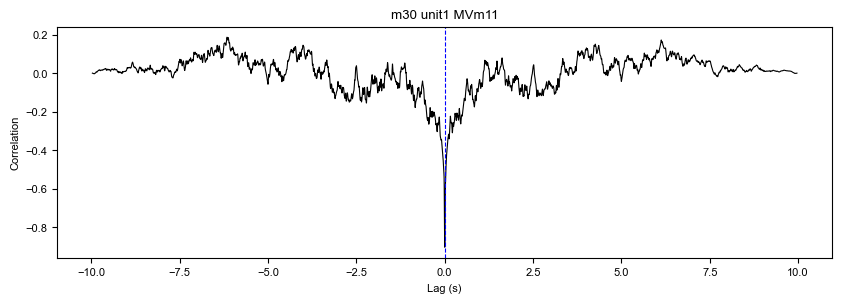

m30 unit1 MVm11: peak=-0.903 at lag=0.0024s | at_zero=-0.887


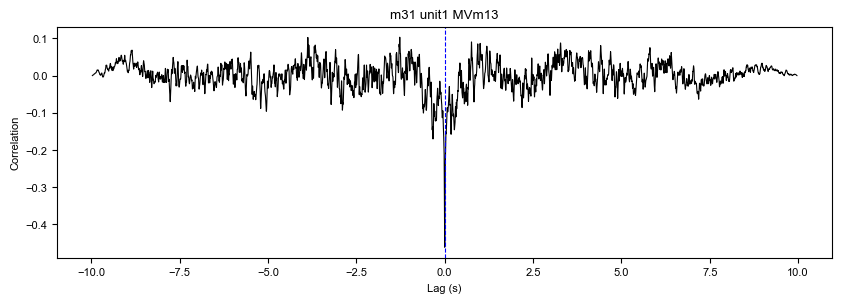

m31 unit1 MVm13: peak=-0.461 at lag=0.0012s | at_zero=-0.458


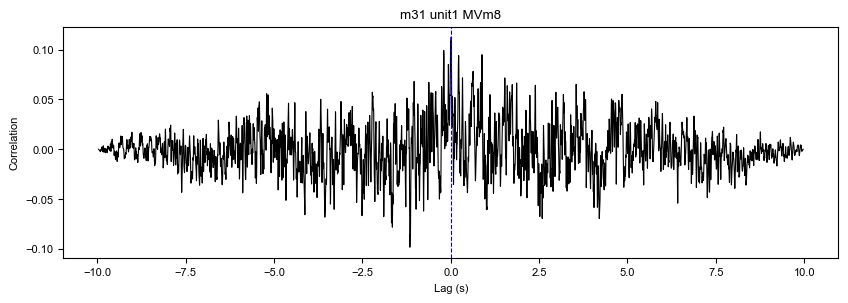

m31 unit1 MVm8: peak=0.112 at lag=0.0112s | at_zero=0.106


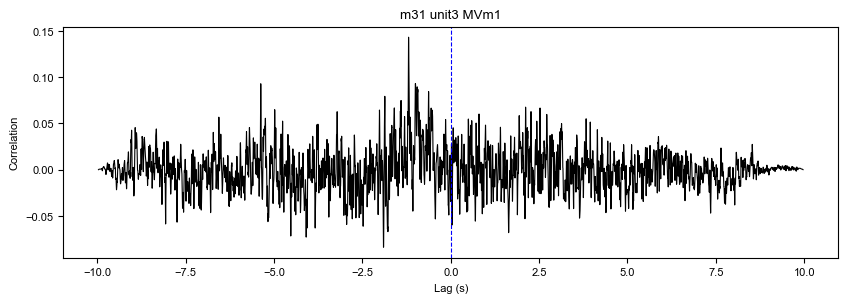

m31 unit3 MVm1: peak=0.143 at lag=-1.1943s | at_zero=-0.033


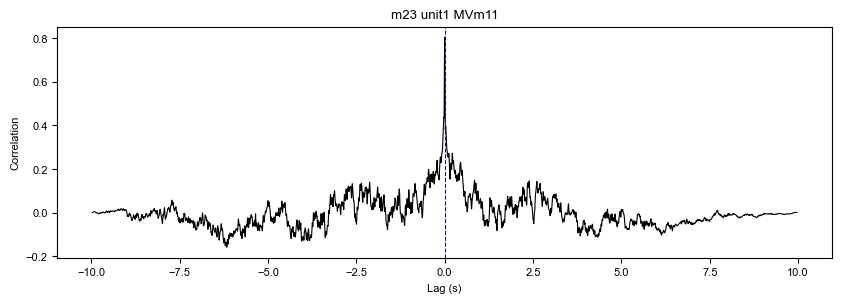

m23 unit1 MVm11: peak=0.804 at lag=0.0003s | at_zero=0.804


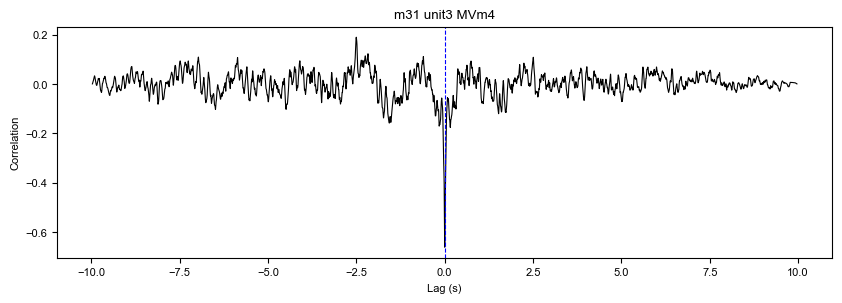

m31 unit3 MVm4: peak=-0.661 at lag=0.0012s | at_zero=-0.659


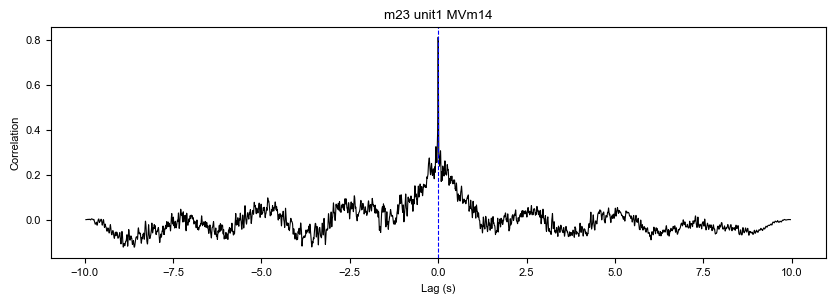

m23 unit1 MVm14: peak=0.810 at lag=0.0004s | at_zero=0.809


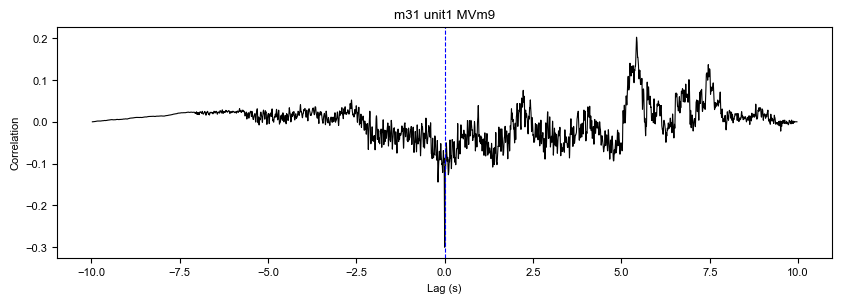

m31 unit1 MVm9: peak=-0.300 at lag=0.0012s | at_zero=-0.297


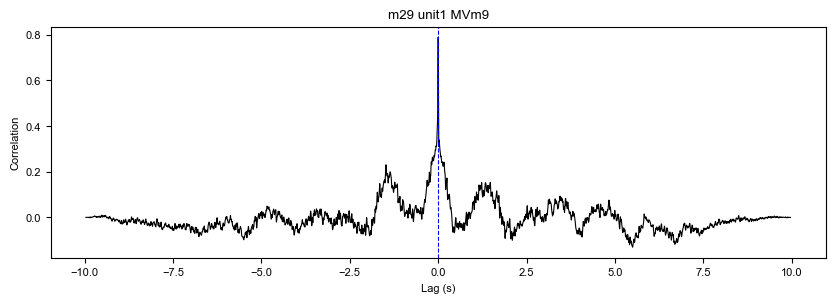

m29 unit1 MVm9: peak=0.790 at lag=0.0002s | at_zero=0.789


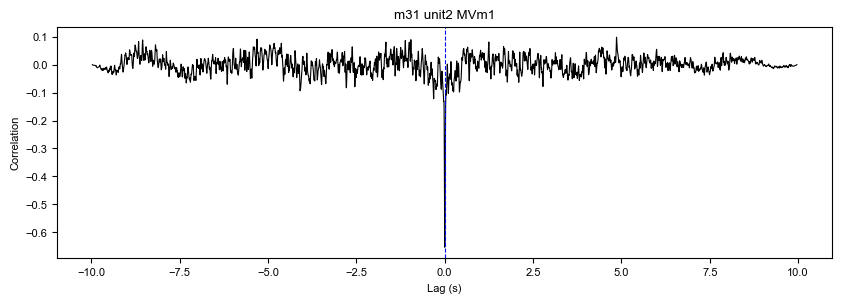

m31 unit2 MVm1: peak=-0.654 at lag=0.0020s | at_zero=-0.640


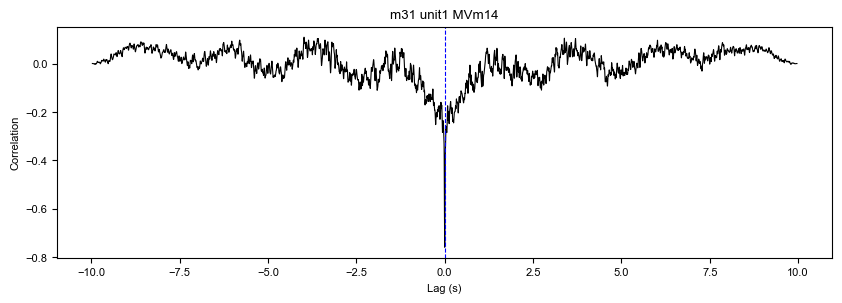

m31 unit1 MVm14: peak=-0.759 at lag=0.0012s | at_zero=-0.754


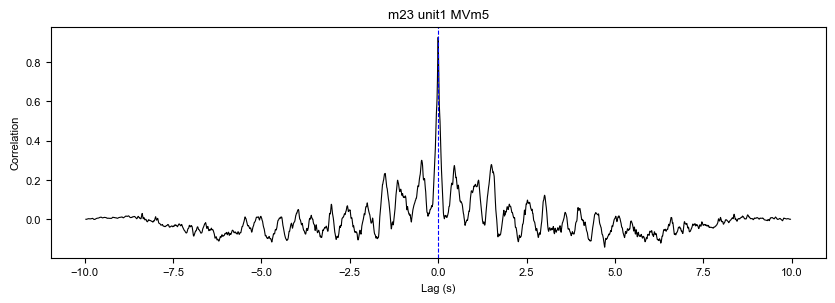

m23 unit1 MVm5: peak=0.925 at lag=-0.0000s | at_zero=0.925


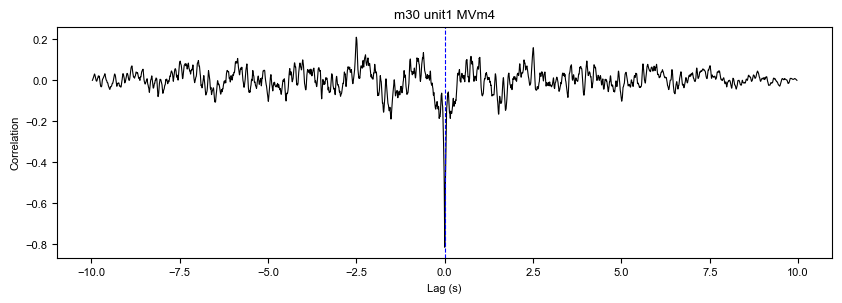

m30 unit1 MVm4: peak=-0.814 at lag=0.0023s | at_zero=-0.800


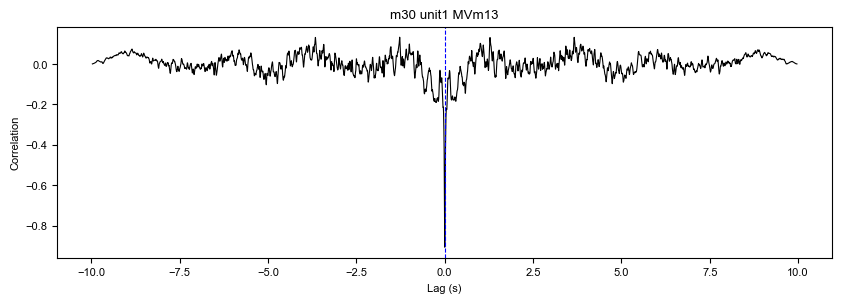

m30 unit1 MVm13: peak=-0.907 at lag=0.0024s | at_zero=-0.887


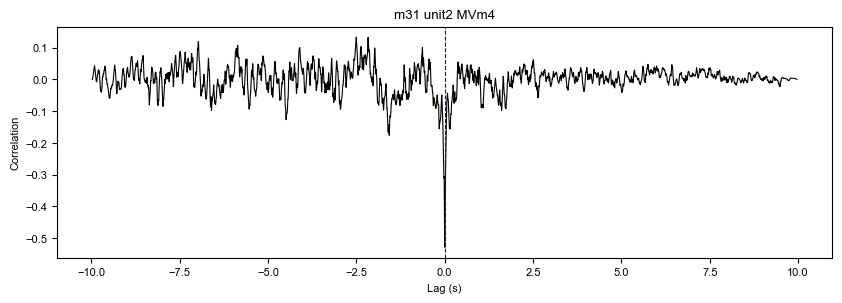

m31 unit2 MVm4: peak=-0.529 at lag=0.0017s | at_zero=-0.523


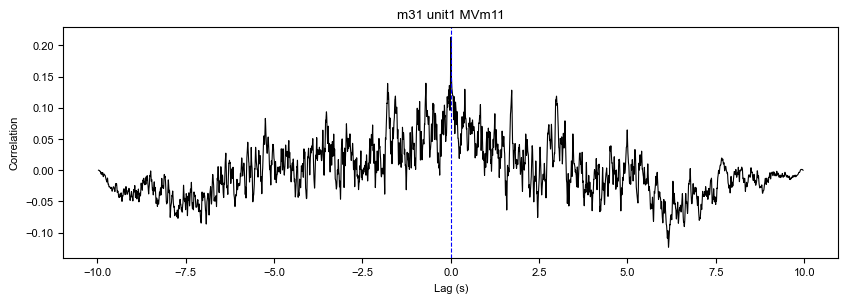

m31 unit1 MVm11: peak=0.213 at lag=0.0017s | at_zero=0.211


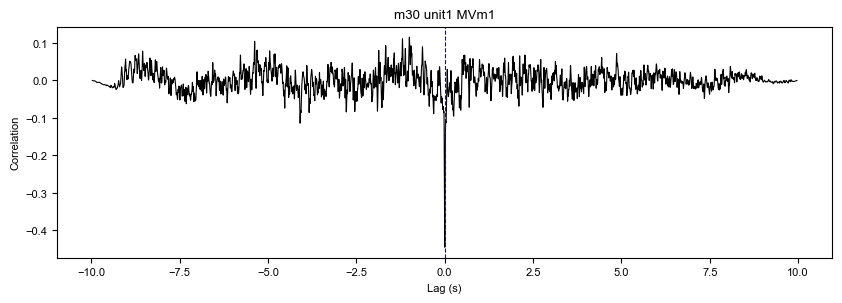

m30 unit1 MVm1: peak=-0.445 at lag=0.0025s | at_zero=-0.432


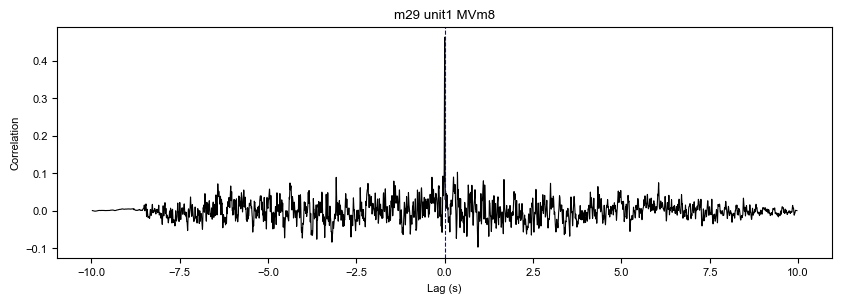

m29 unit1 MVm8: peak=0.462 at lag=0.0004s | at_zero=0.462


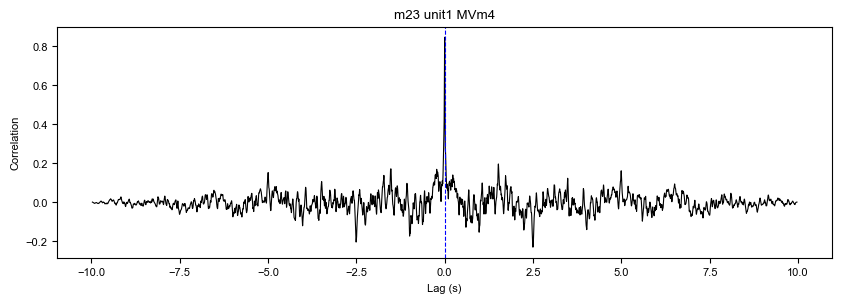

m23 unit1 MVm4: peak=0.846 at lag=0.0002s | at_zero=0.846


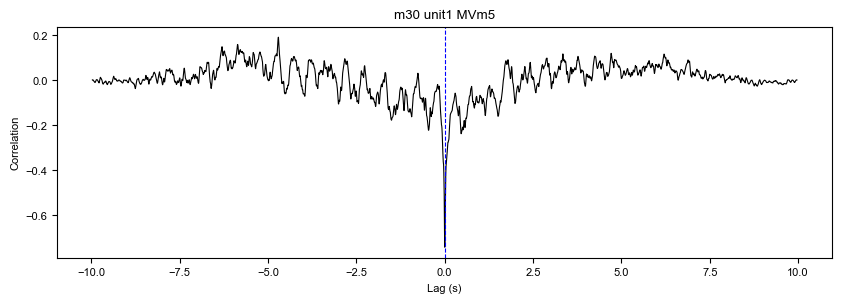

m30 unit1 MVm5: peak=-0.743 at lag=0.0026s | at_zero=-0.731


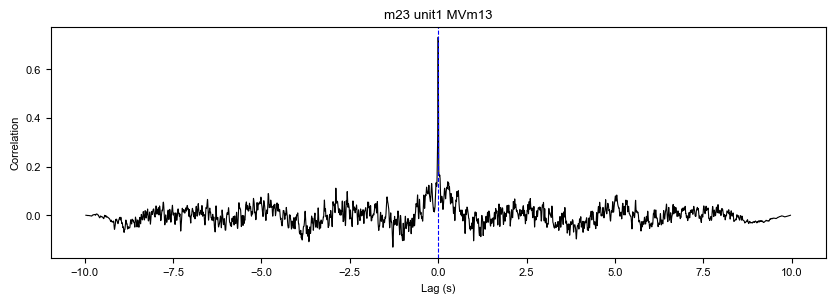

m23 unit1 MVm13: peak=0.731 at lag=0.0003s | at_zero=0.731


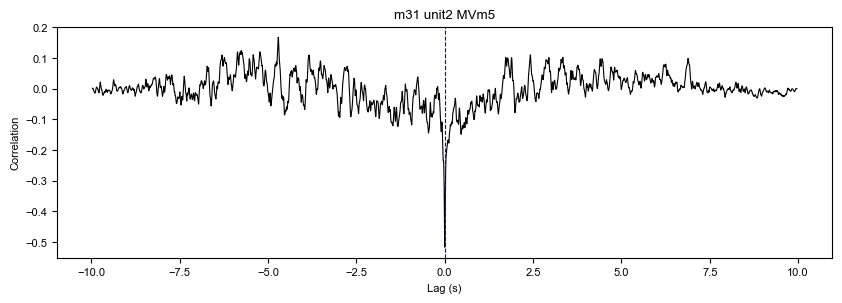

m31 unit2 MVm5: peak=-0.517 at lag=0.0018s | at_zero=-0.512


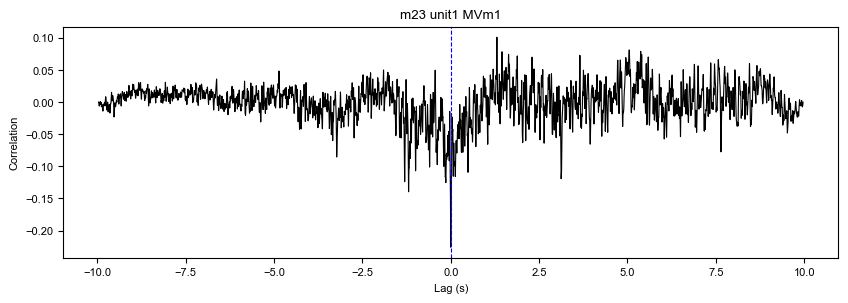

m23 unit1 MVm1: peak=-0.226 at lag=0.0000s | at_zero=-0.226


In [6]:
for filepath in glob.glob('./dataFolder/6_NaturalBehavior/Clipped_test/v2/*_Prediction.pickle'):
    with open(filepath, 'rb') as f:
        savedData = pickle.load(f)

    moth     = os.path.basename(filepath).split('_')[0]
    unitID   = os.path.basename(filepath).split('_')[1]
    vid_moth = os.path.basename(filepath).split('_')[3]

#     if moth != 'm31' or unit != unit2:
#             continue
    
    df_proj   = savedData[2]
    upsampled = savedData[3]

    p_spike  = df_proj['pred_max'].values  # swap to pred_max to compare
    
    predcorr = np.correlate(p_spike - np.mean(p_spike),
                        upsampled - np.mean(upsampled), mode='full')
    predcorr_normalised = predcorr / (len(p_spike) * np.std(p_spike) * np.std(upsampled))
    lags     = np.arange(-(len(p_spike)-1), len(p_spike)) / Fs
    peak_idx = np.argmax(np.abs(predcorr_normalised))
    zero_idx = np.argmin(np.abs(lags))
    
    


    plt.figure(figsize=(10, 3))
    plt.plot(lags, predcorr_normalised, 'k', linewidth=0.8)
    plt.axvline(0, color='blue', linestyle='--', linewidth=0.8)
    plt.xlabel('Lag (s)')
    plt.ylabel('Correlation')
    plt.title(f'{moth} {unitID} {vid_moth}')
    plt.savefig(out_fig + moth + '_' + unitID + '_' + vid_moth +'_crosscor.pdf')
    plt.show()
    plt.close()
    print(f'{moth} {unitID} {vid_moth}: peak={predcorr_normalised[peak_idx]:.3f} at lag={lags[peak_idx]:.4f}s | at_zero={predcorr_normalised[zero_idx]:.3f}')

    predcorr_df = pd.DataFrame({'lag_seconds': lags, 'predcorr_normalised': predcorr_normalised})
    predcorr_df.to_csv(out_path + moth + '_' + unitID + '_for_' + vid_moth + '_predcorrnorm.csv', index=False)

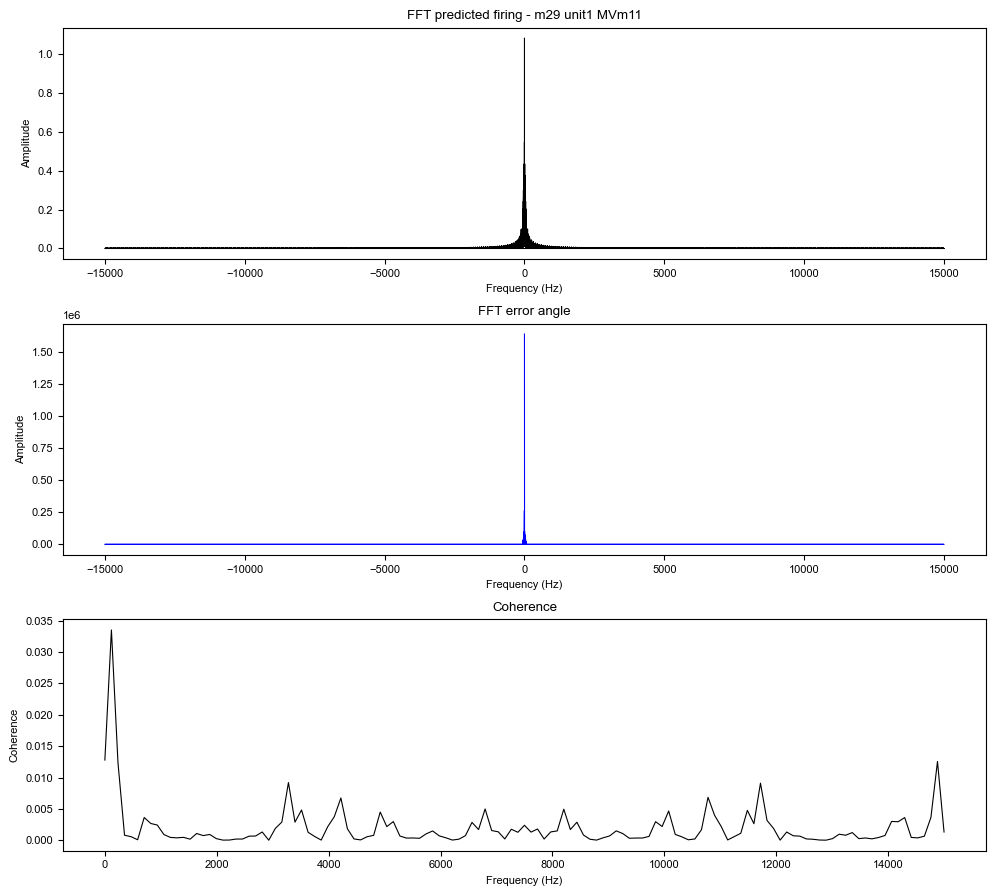

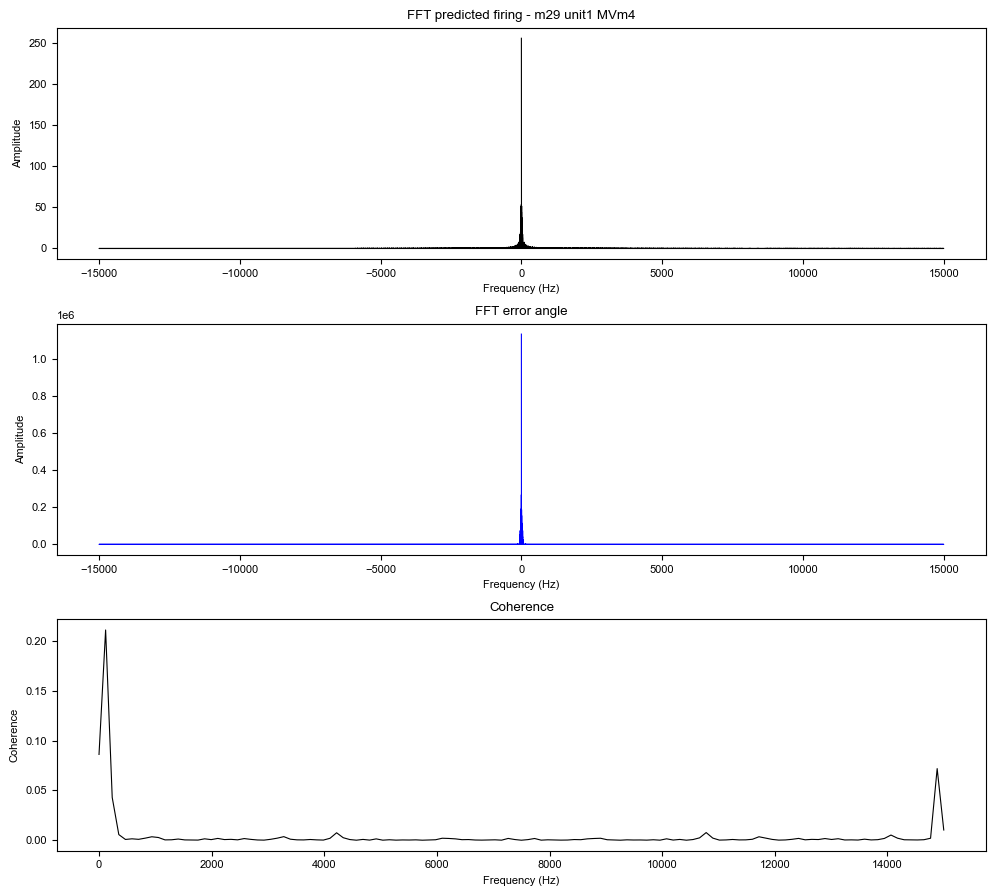

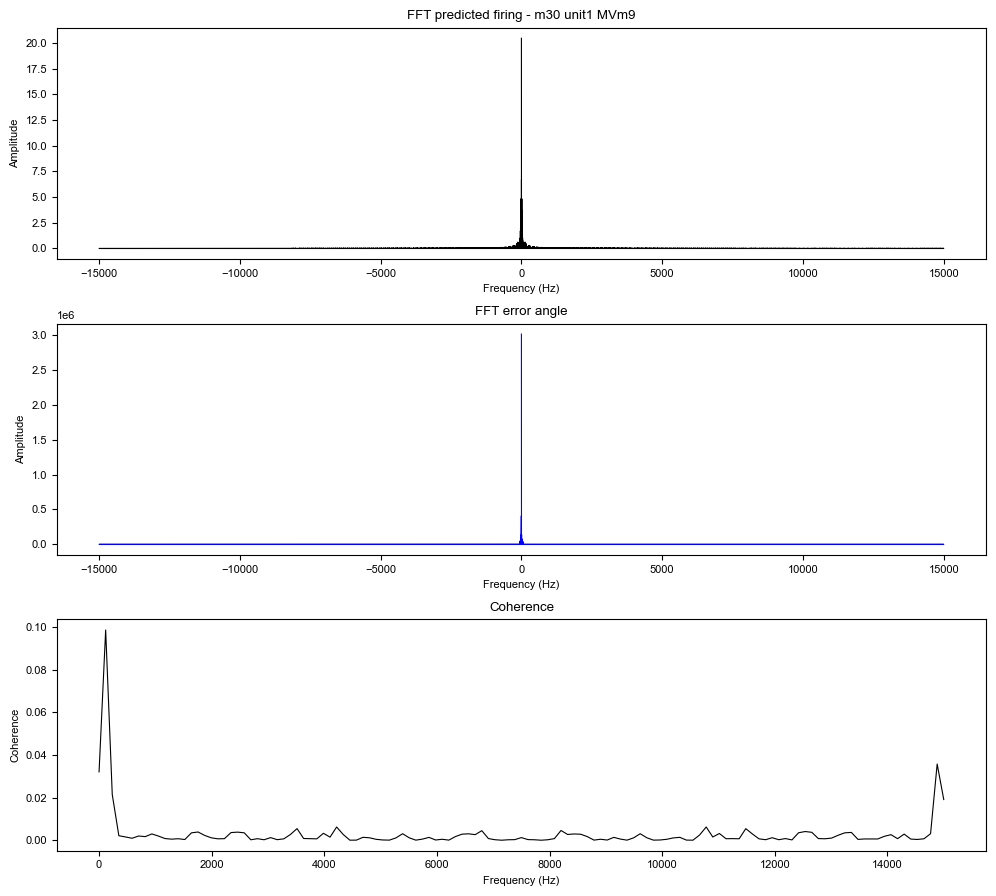

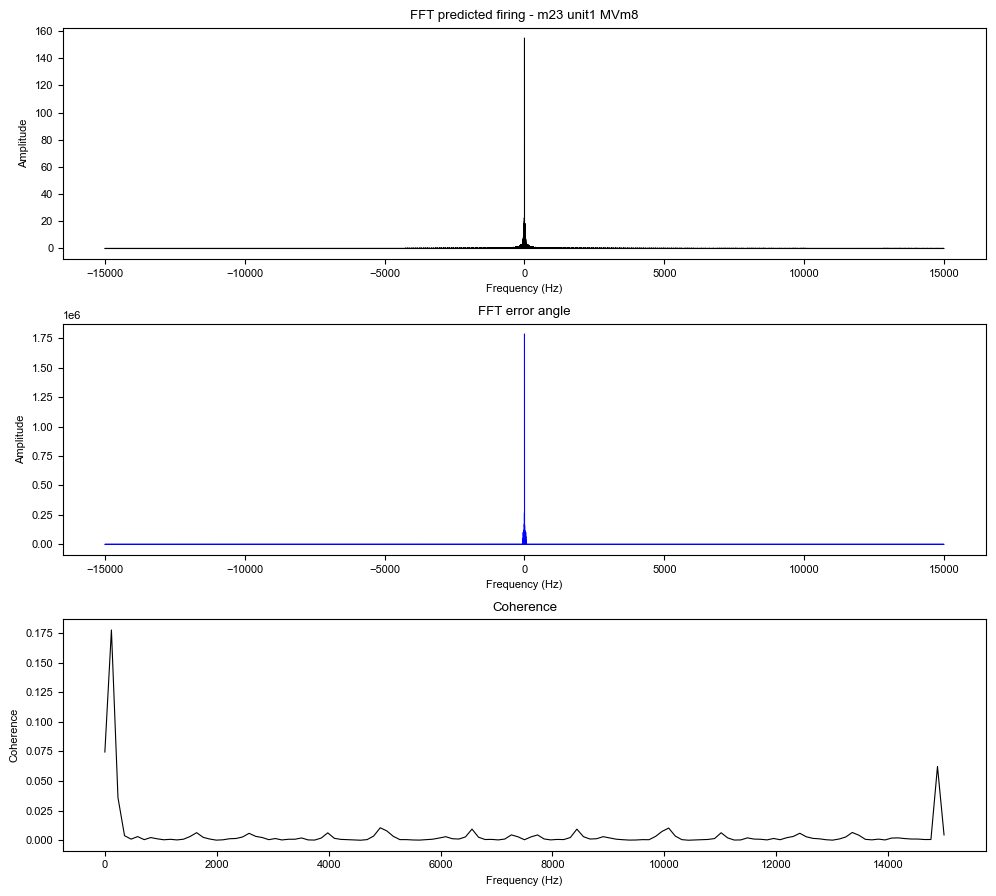

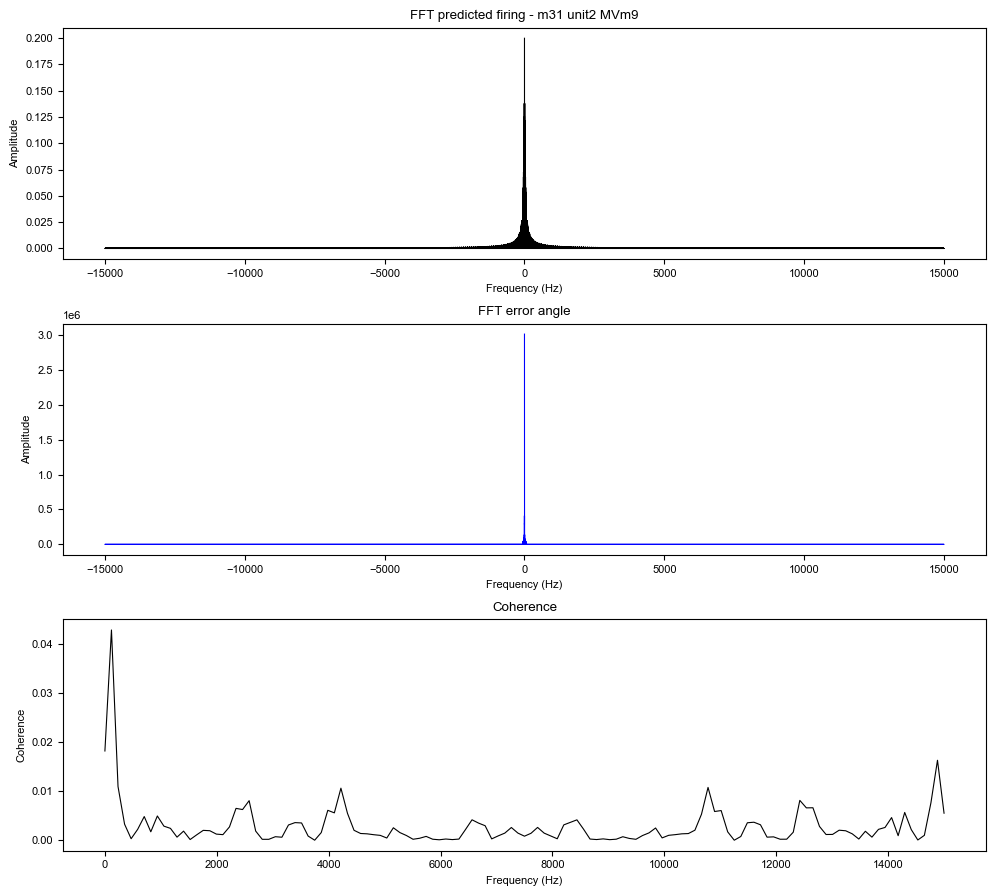

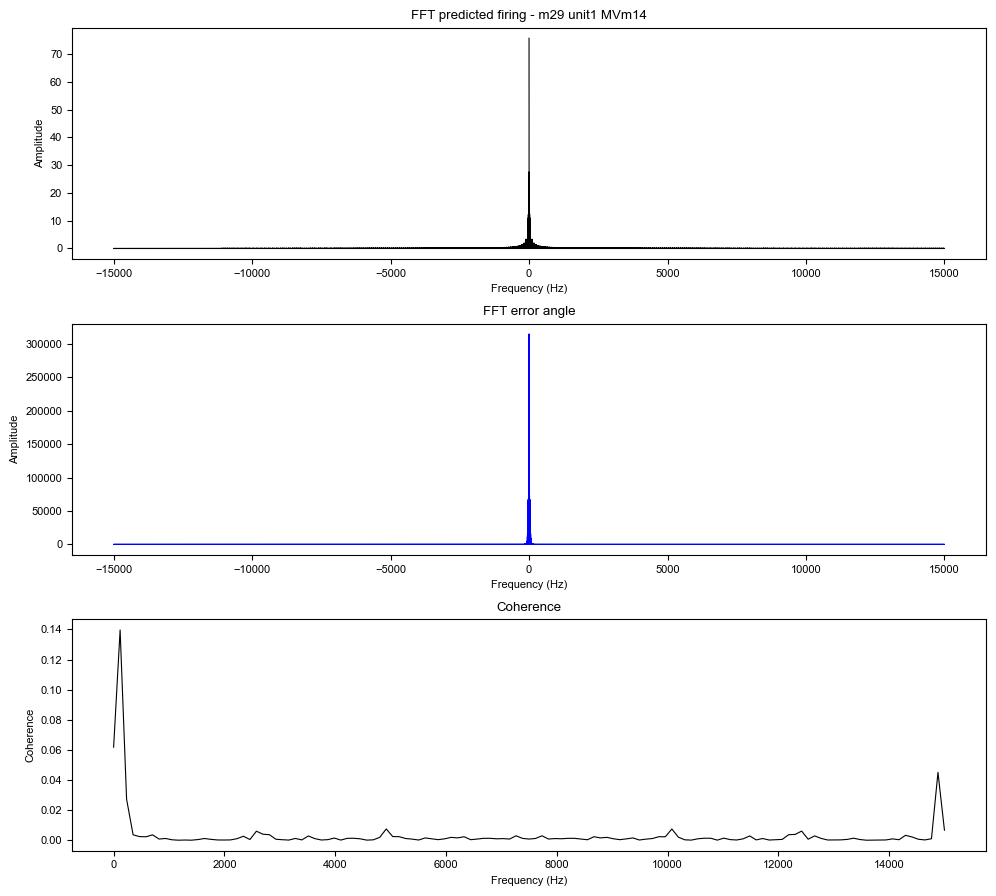

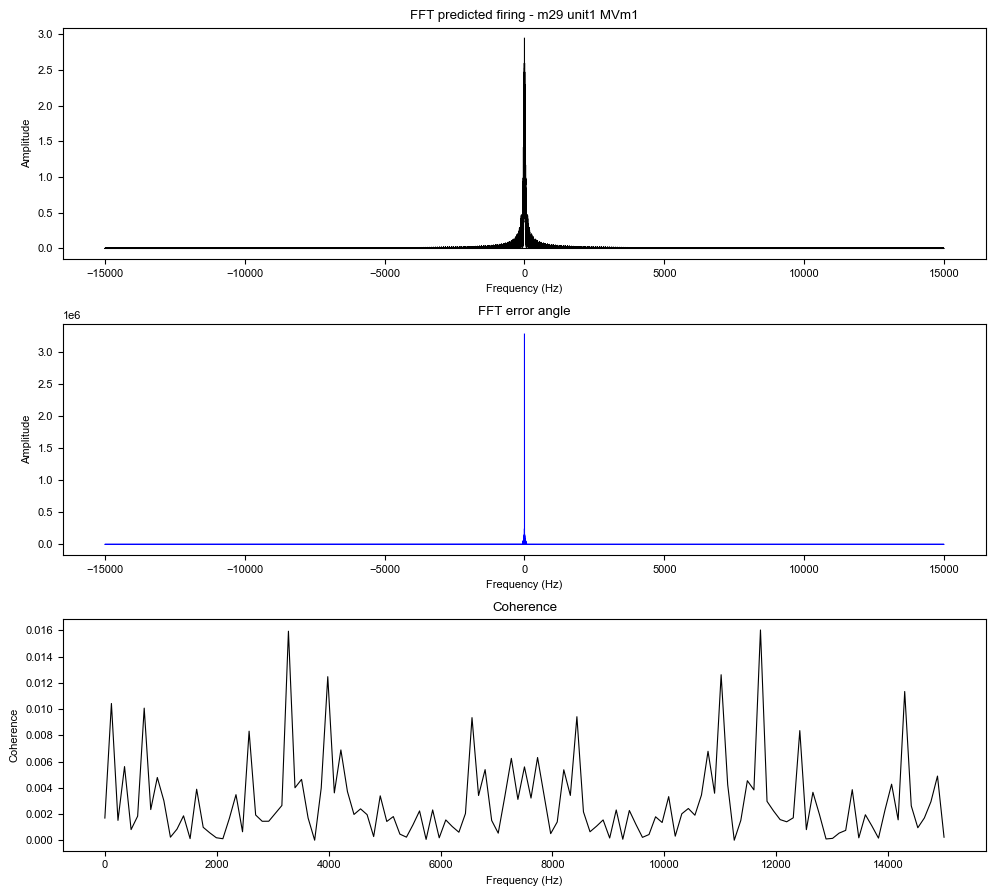

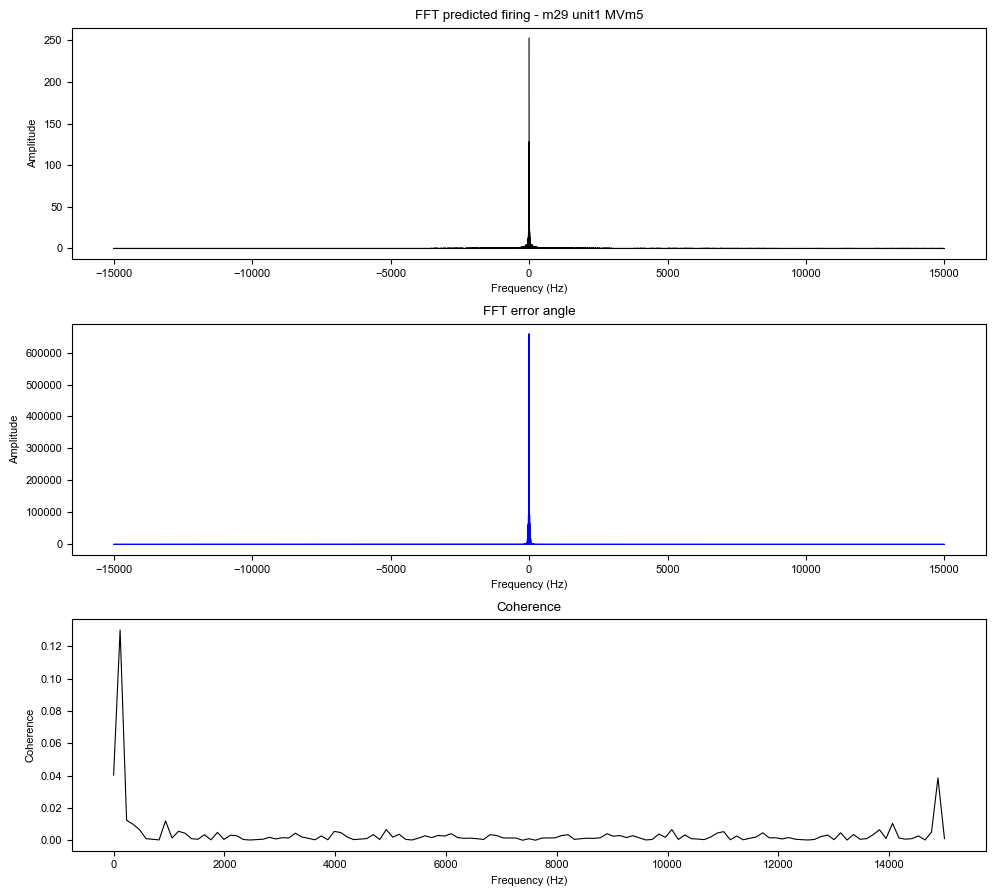

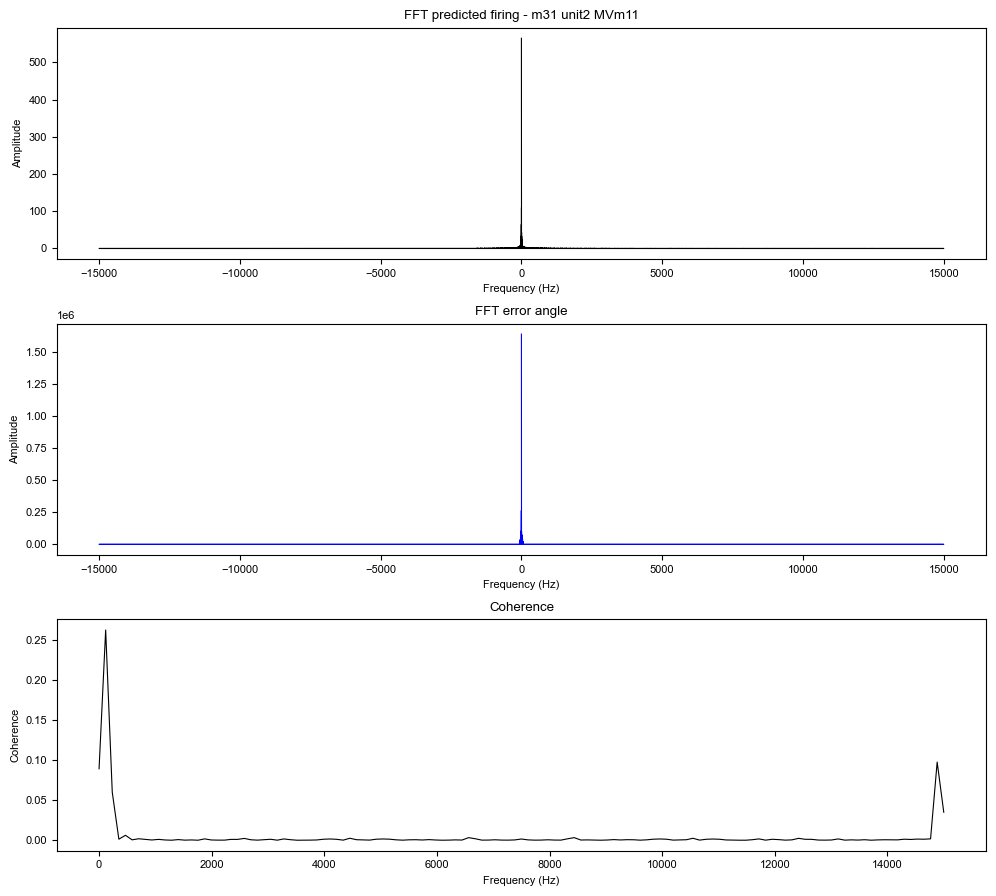

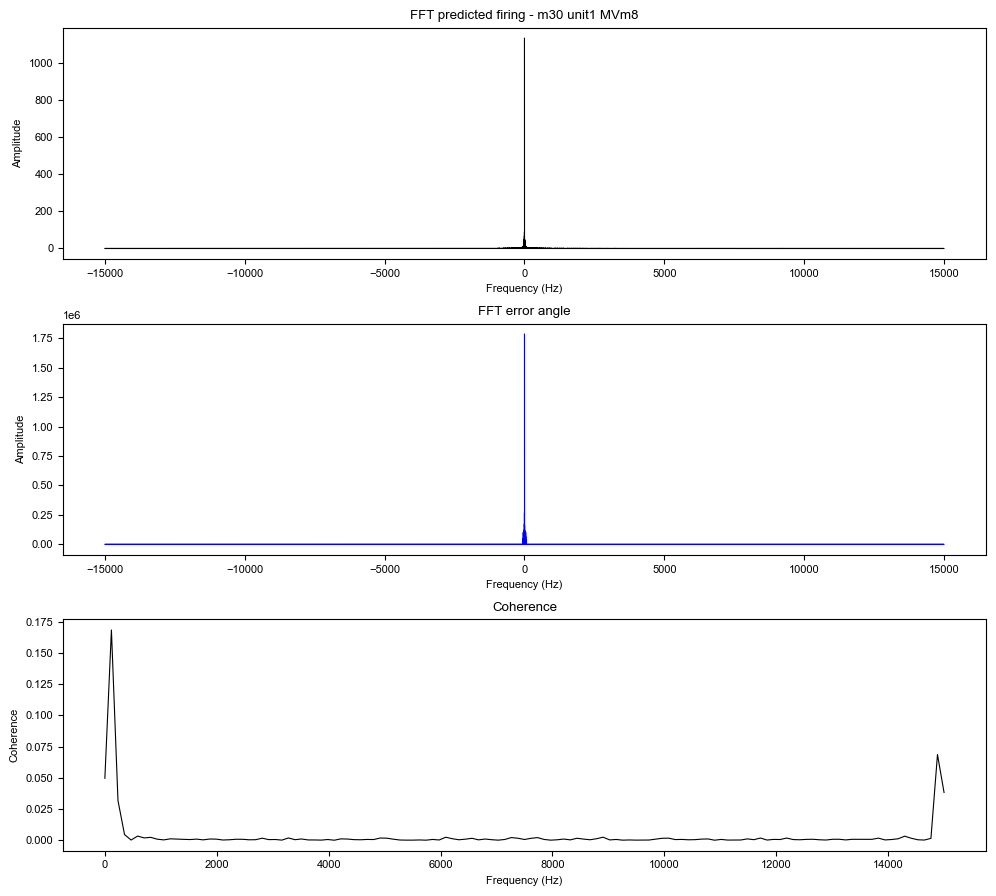

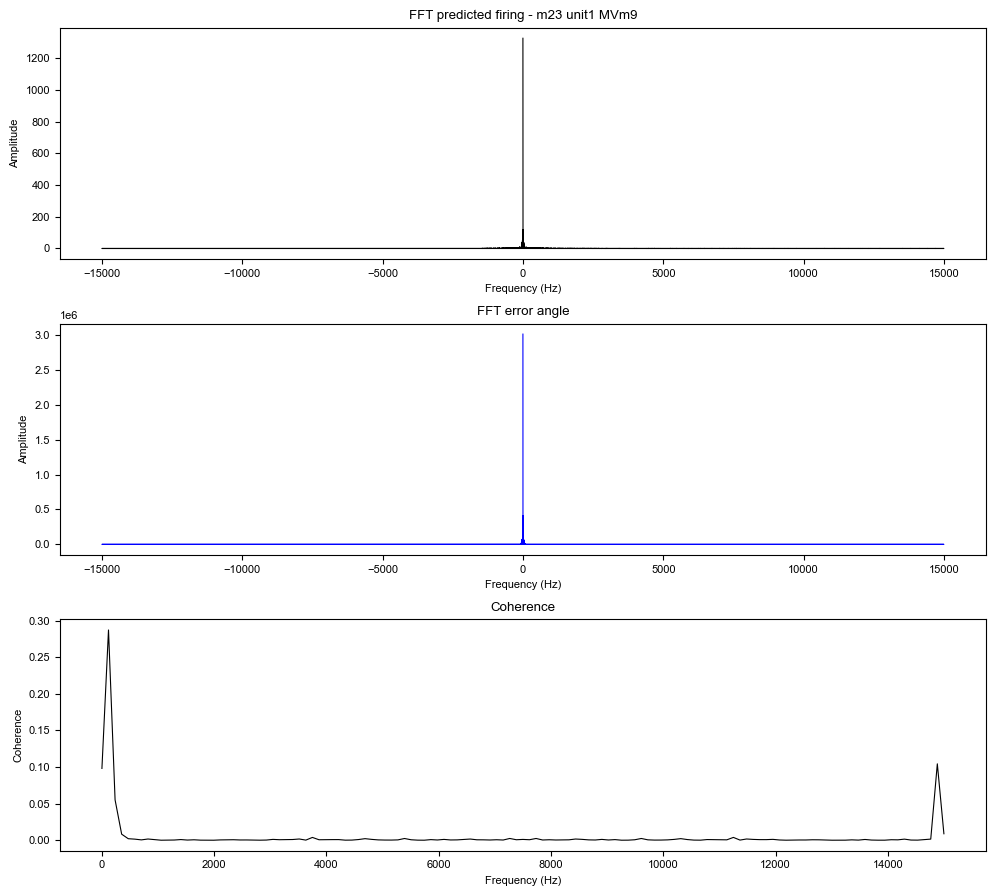

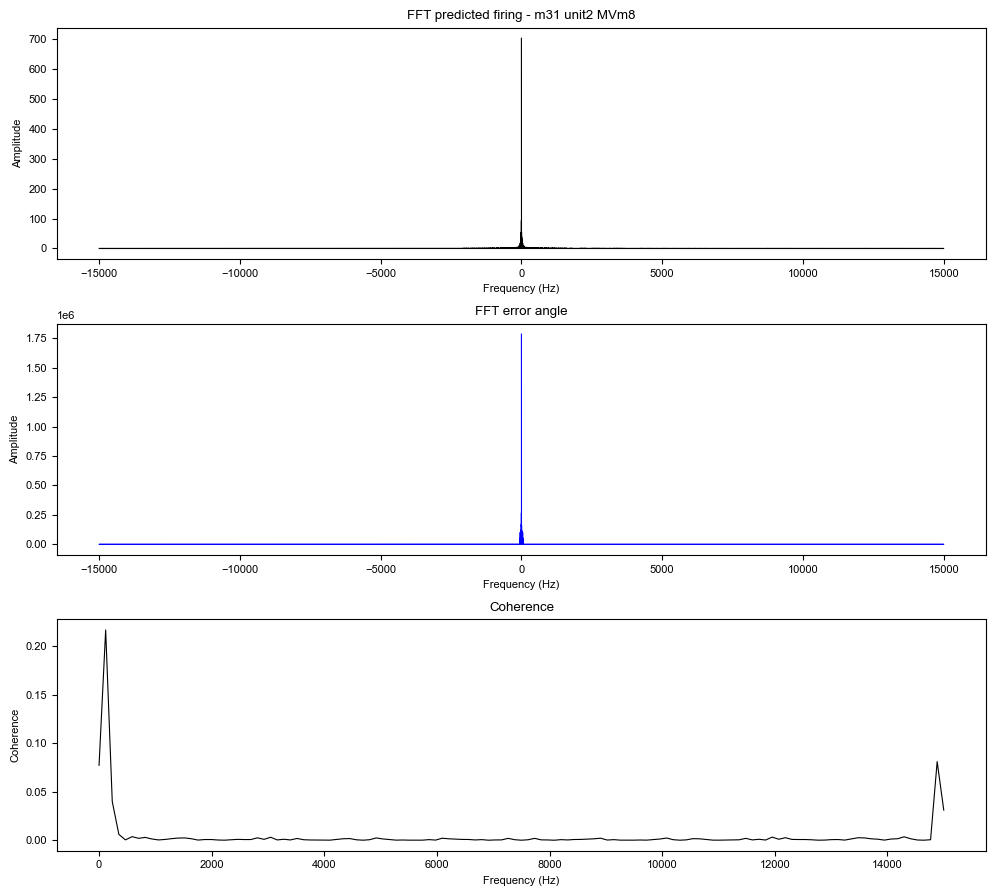

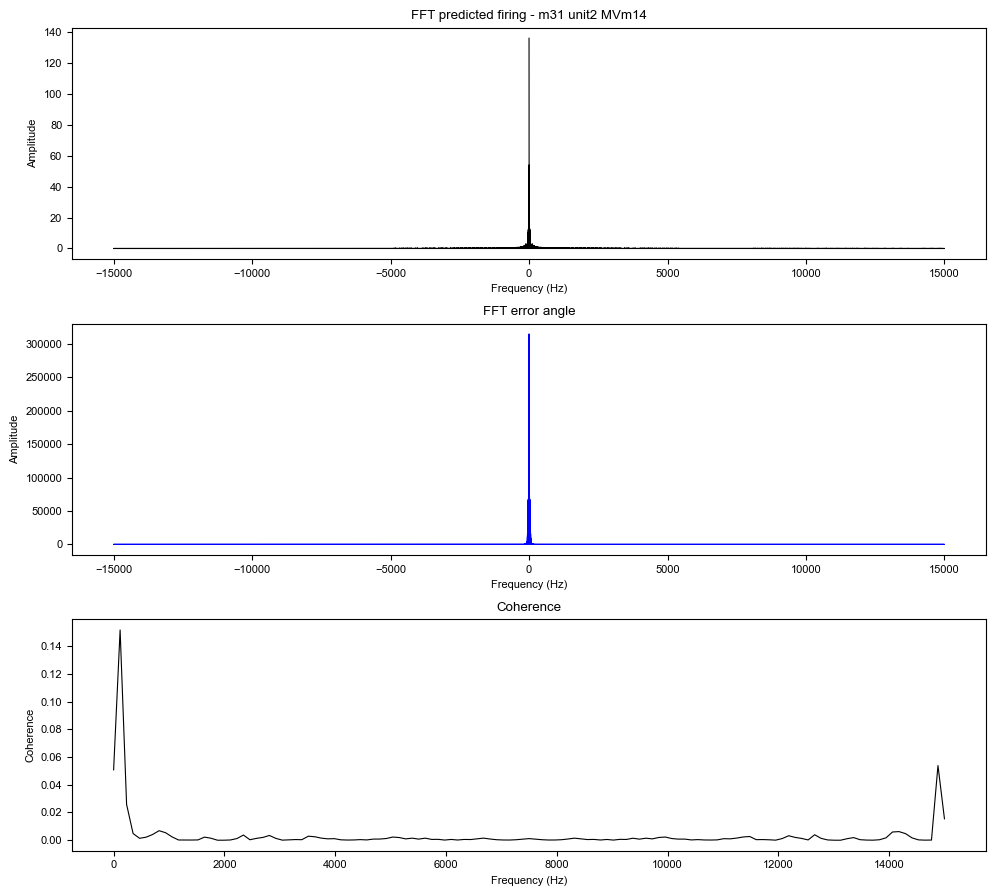

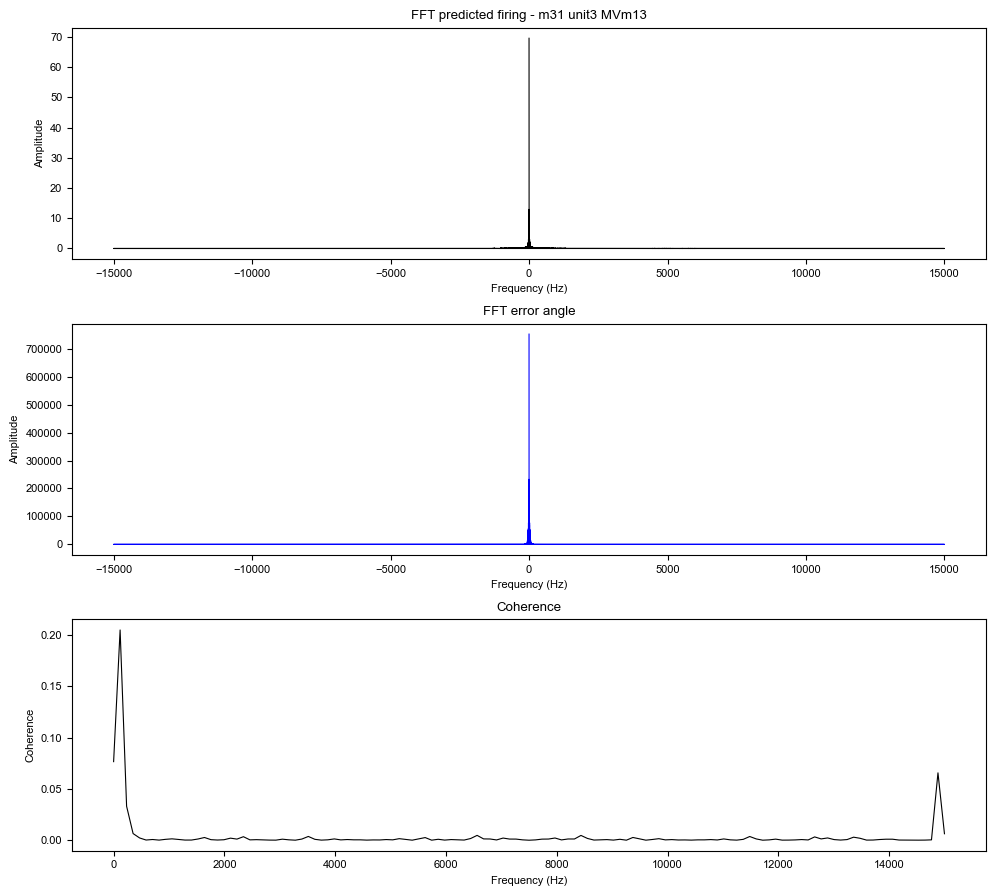

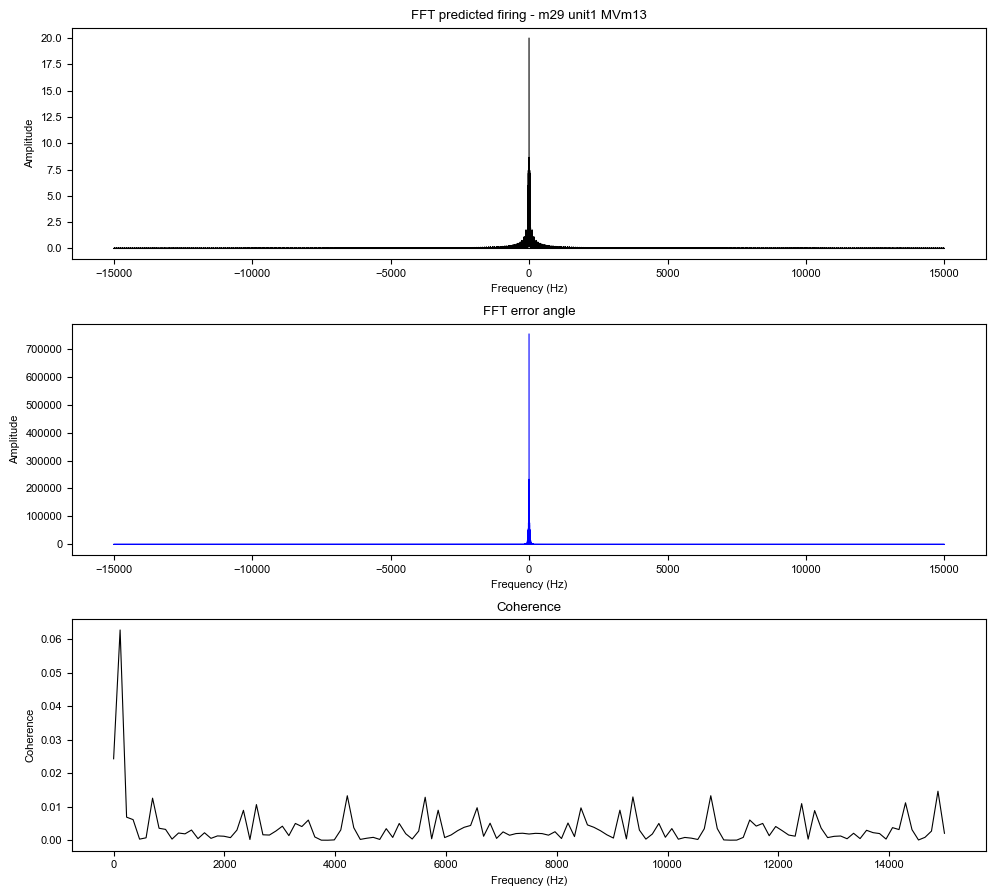

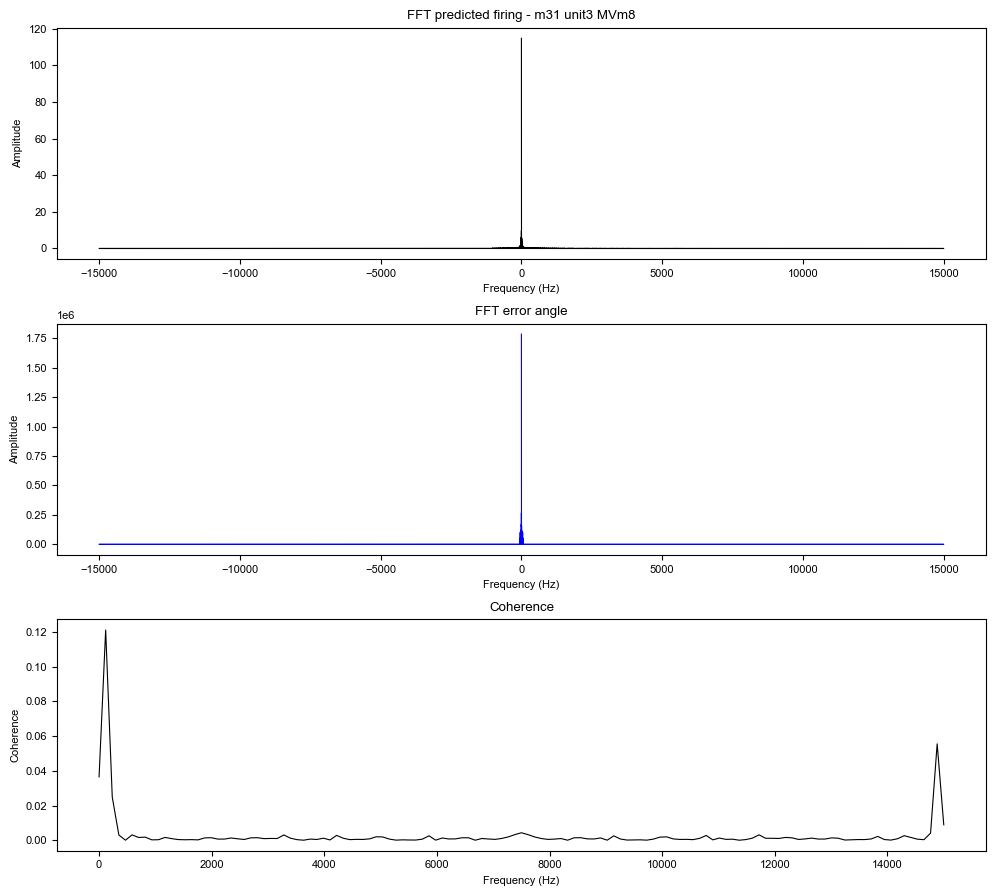

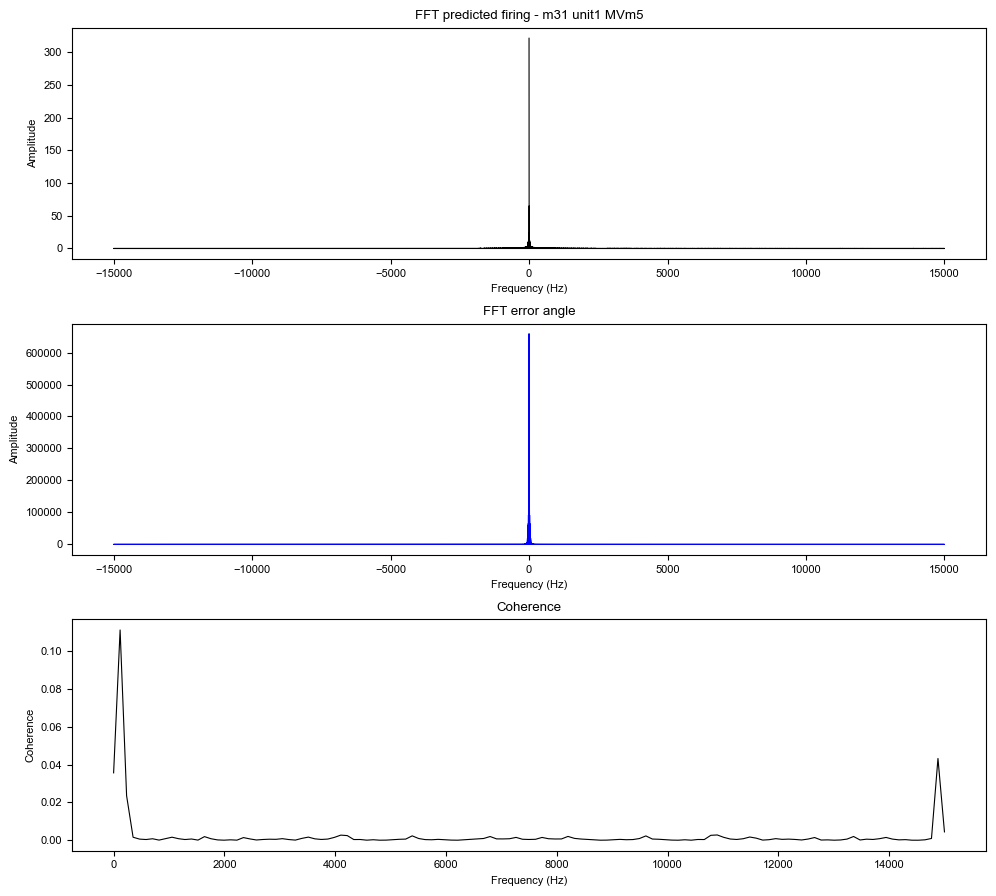

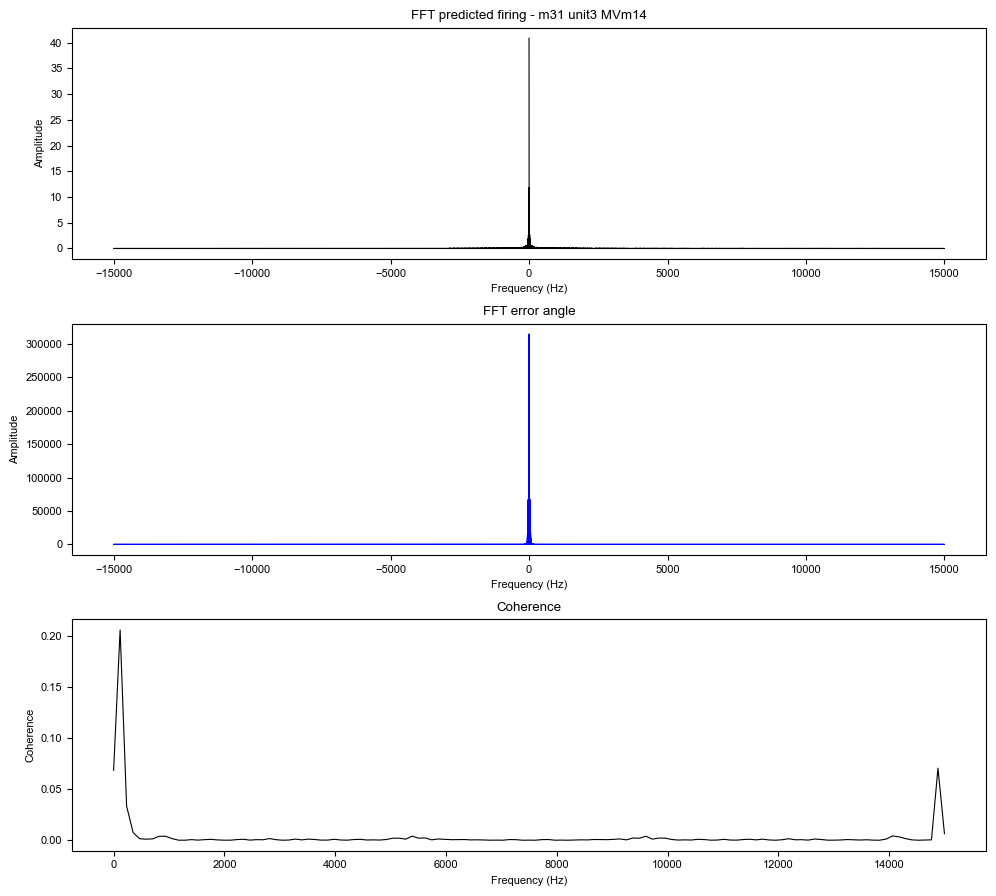

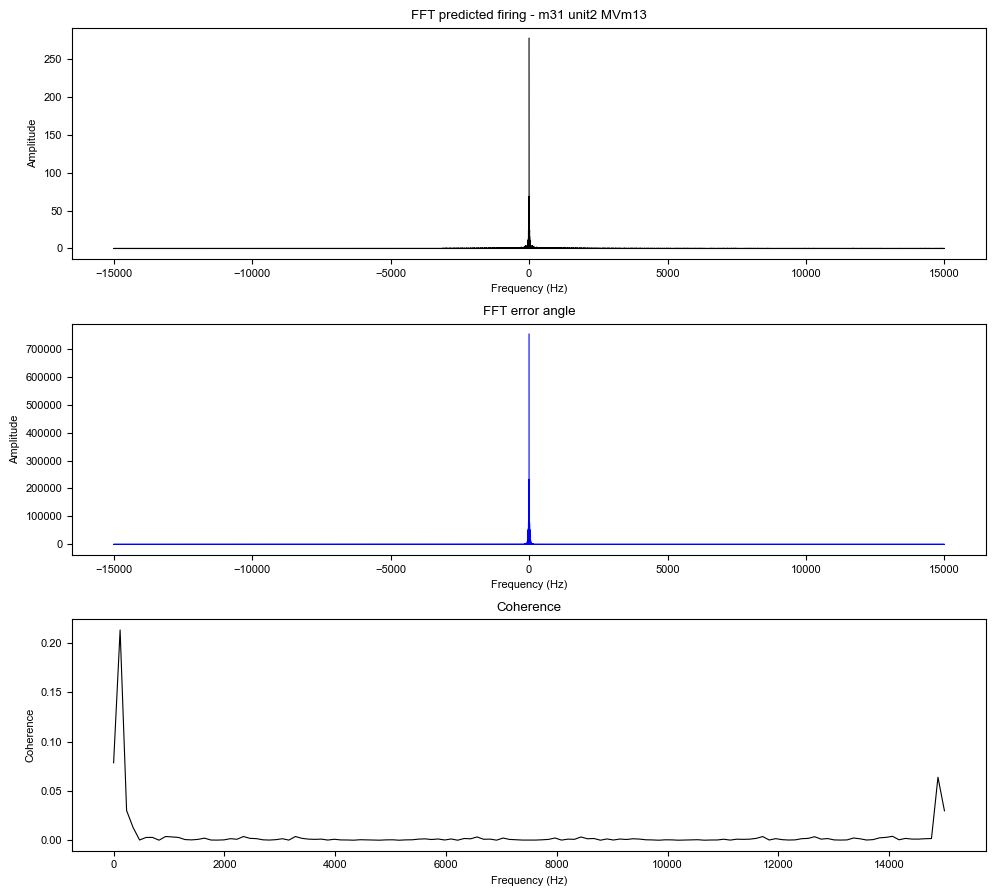

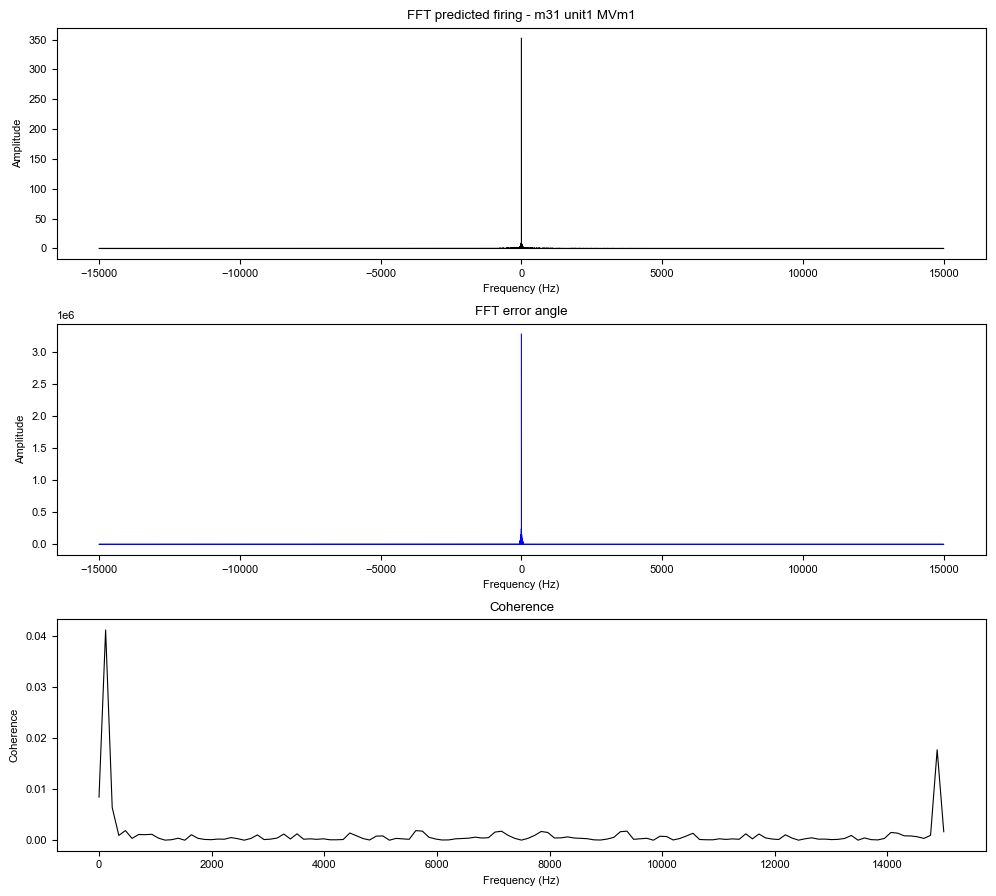

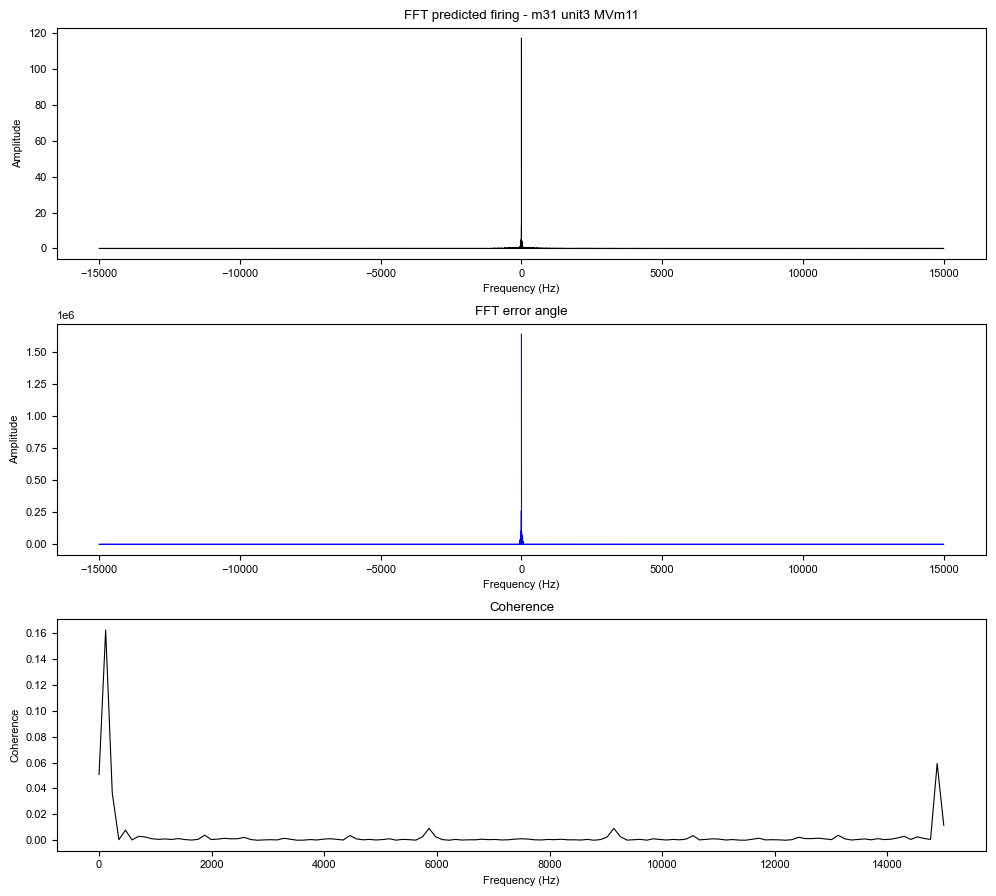

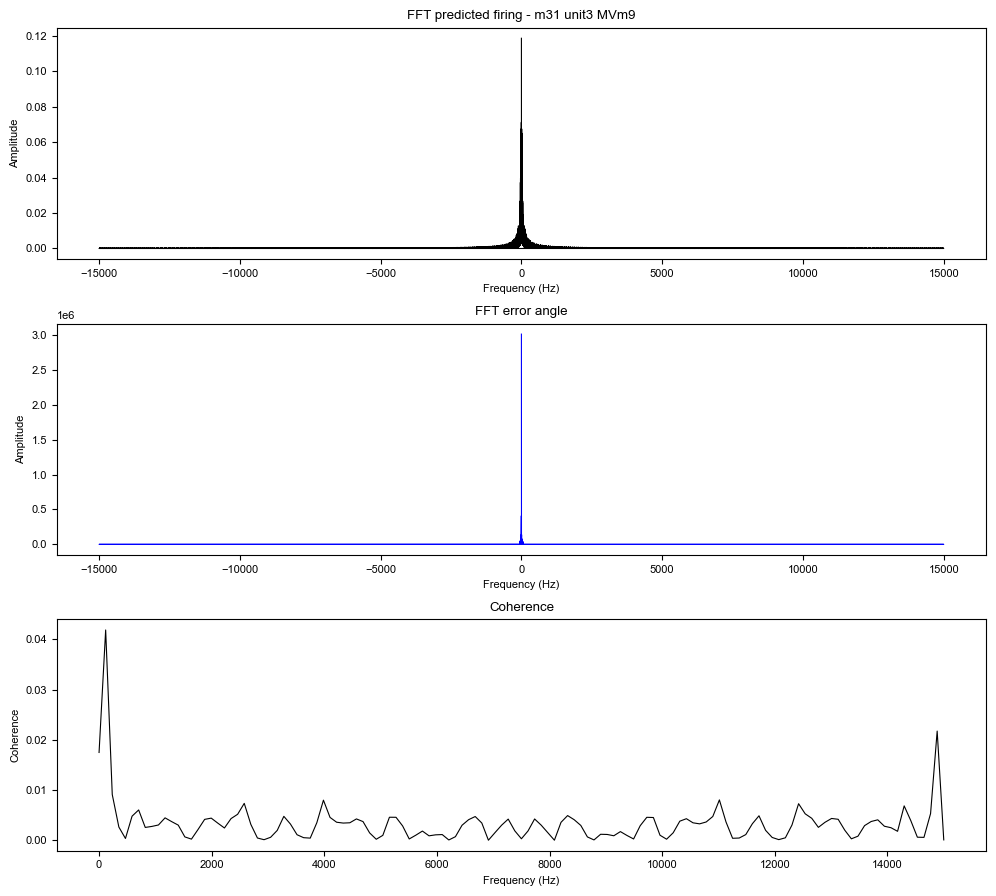

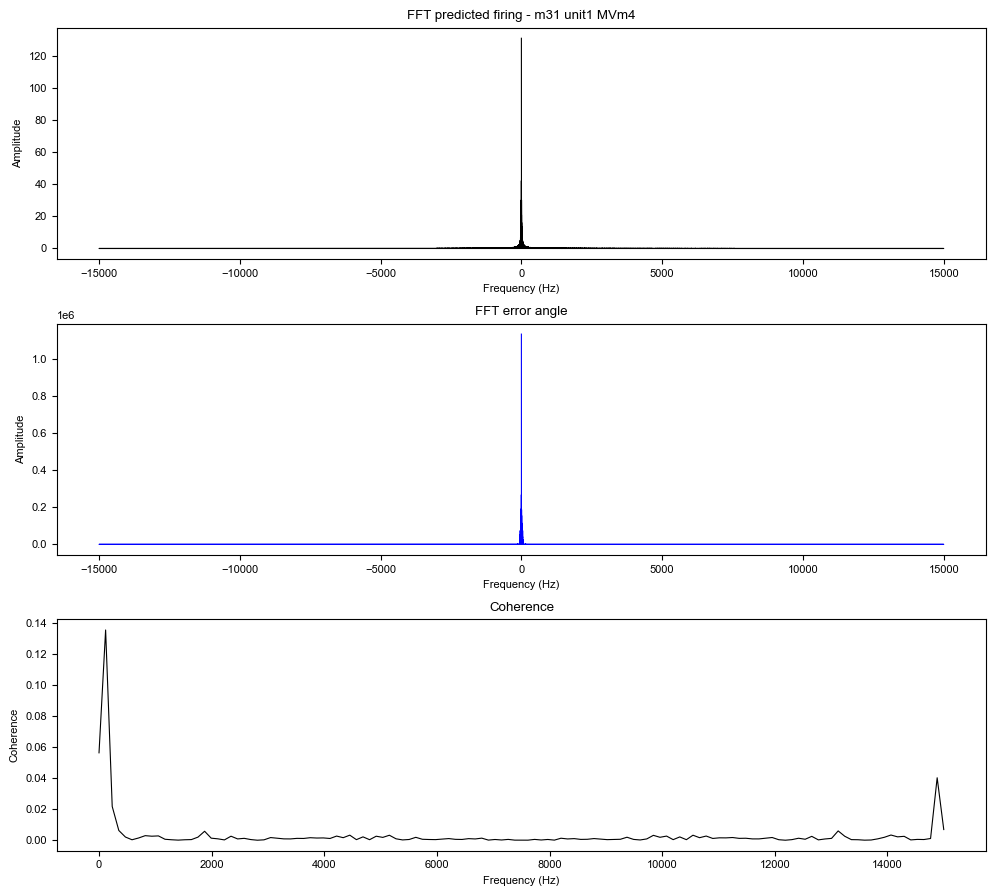

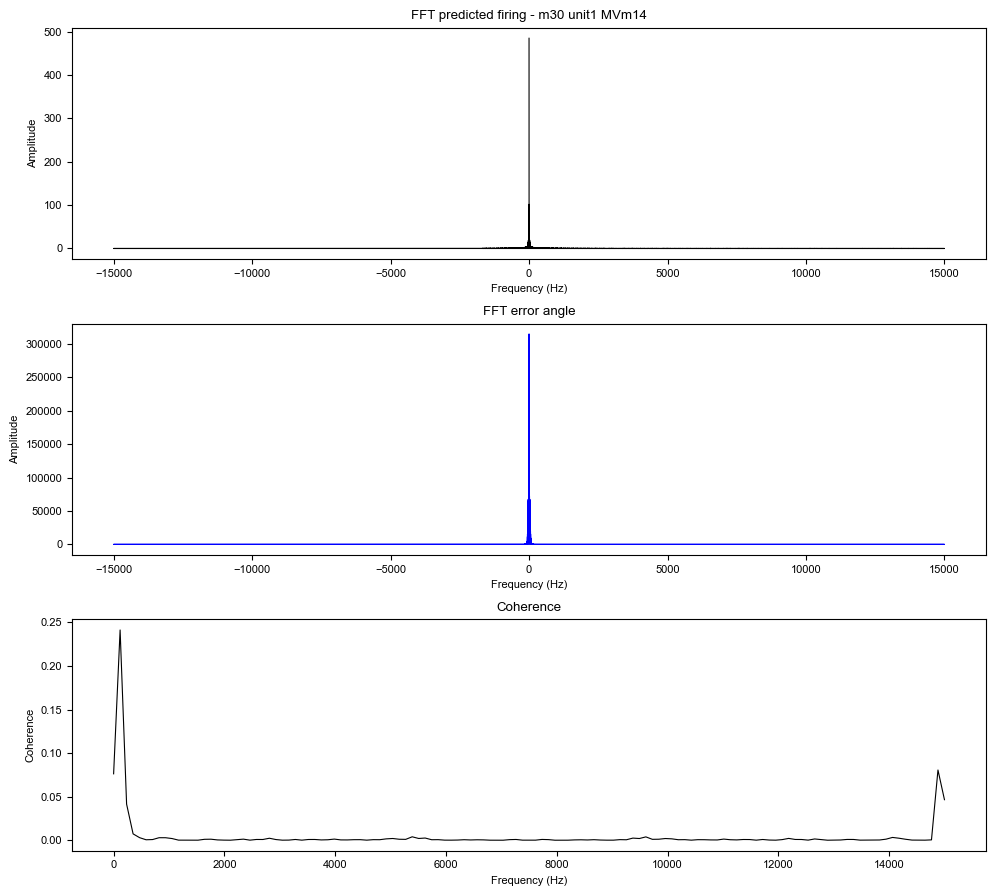

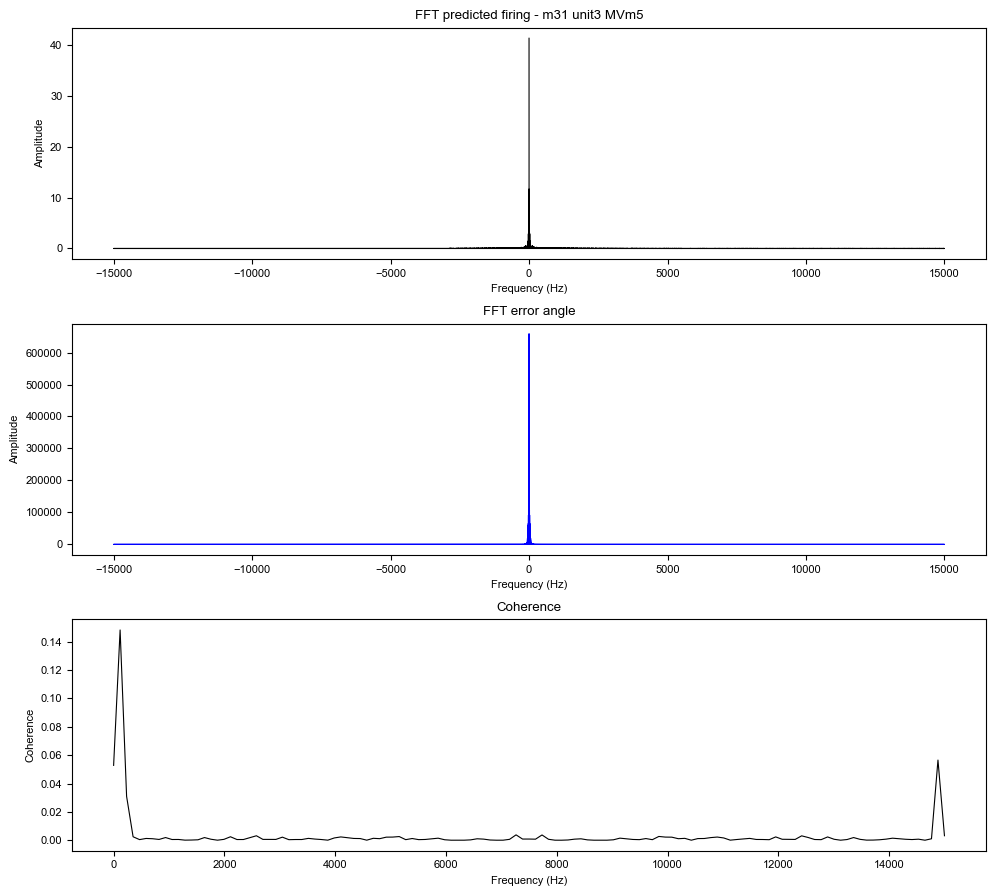

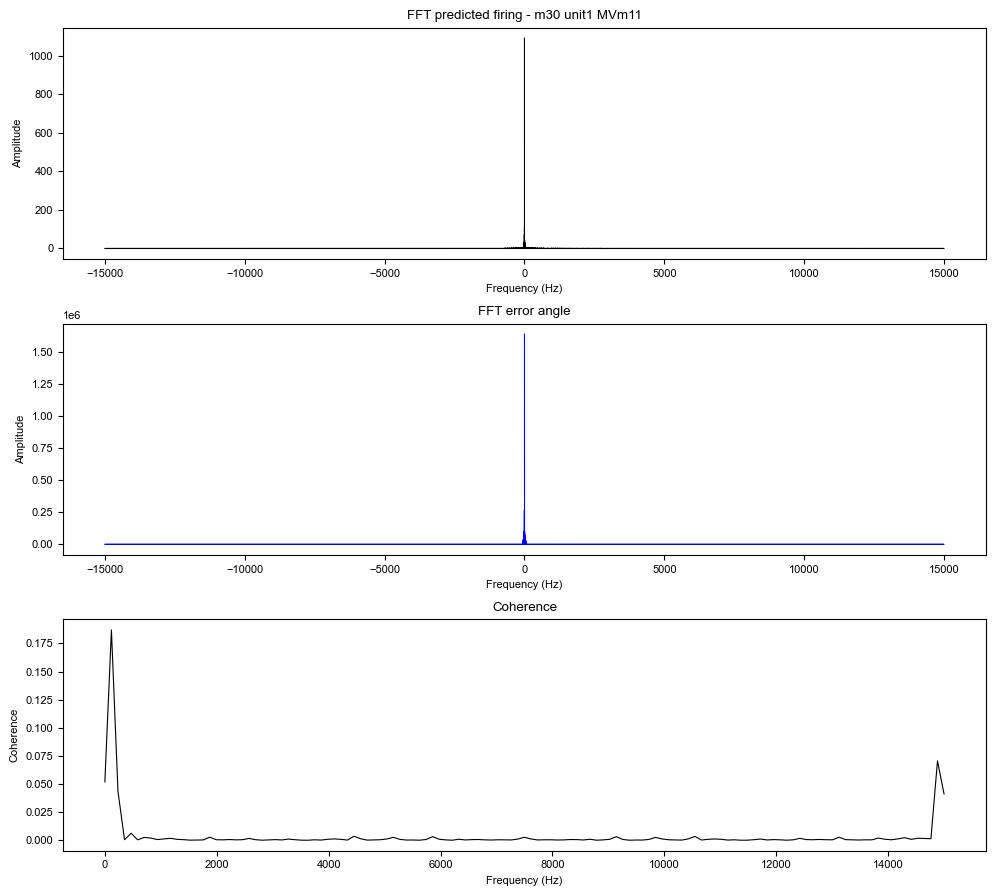

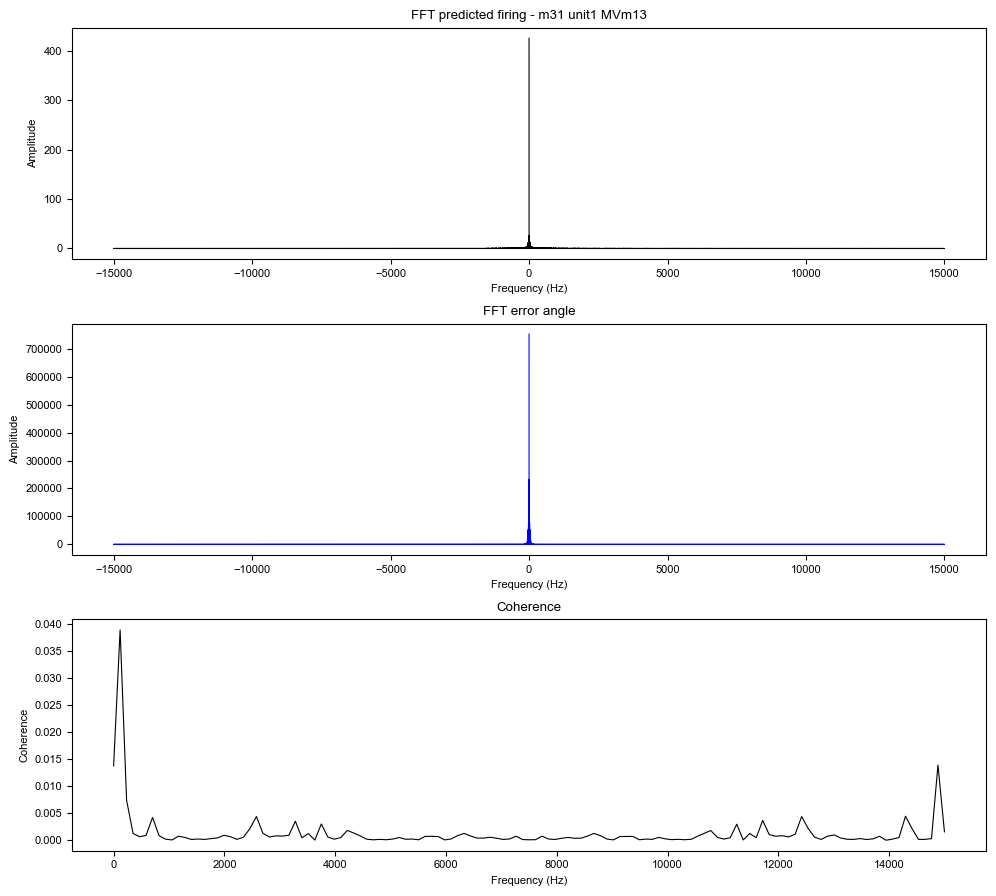

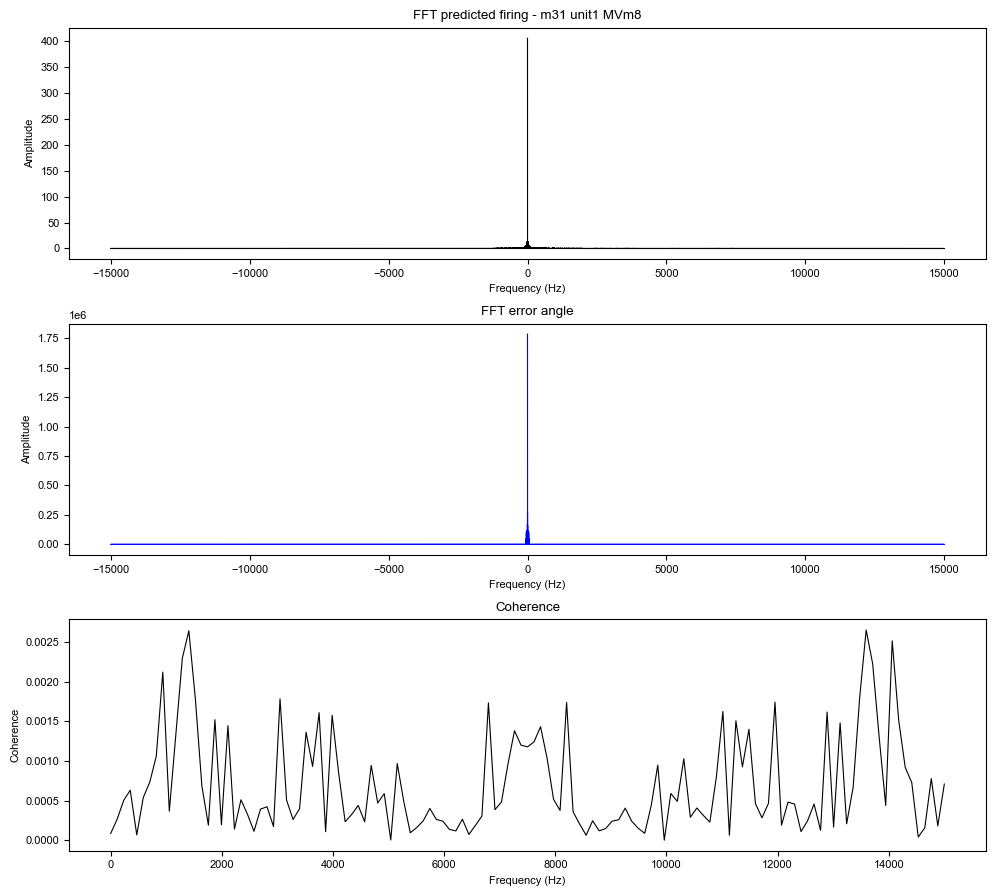

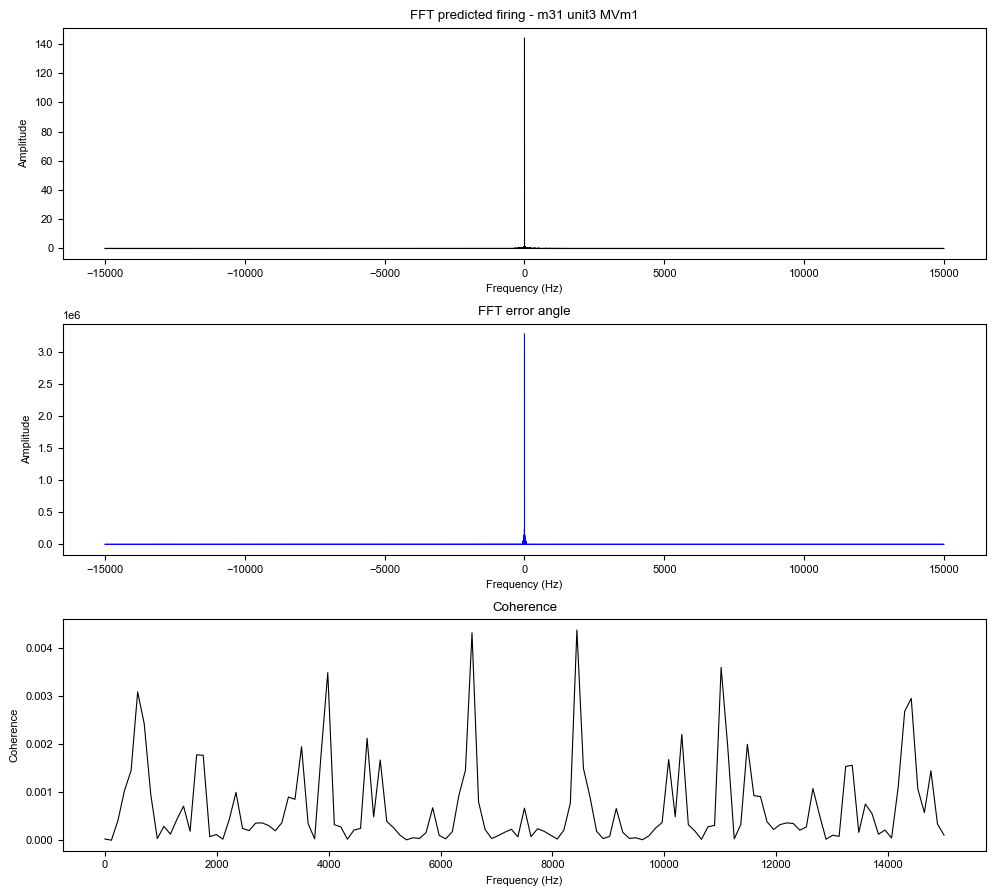

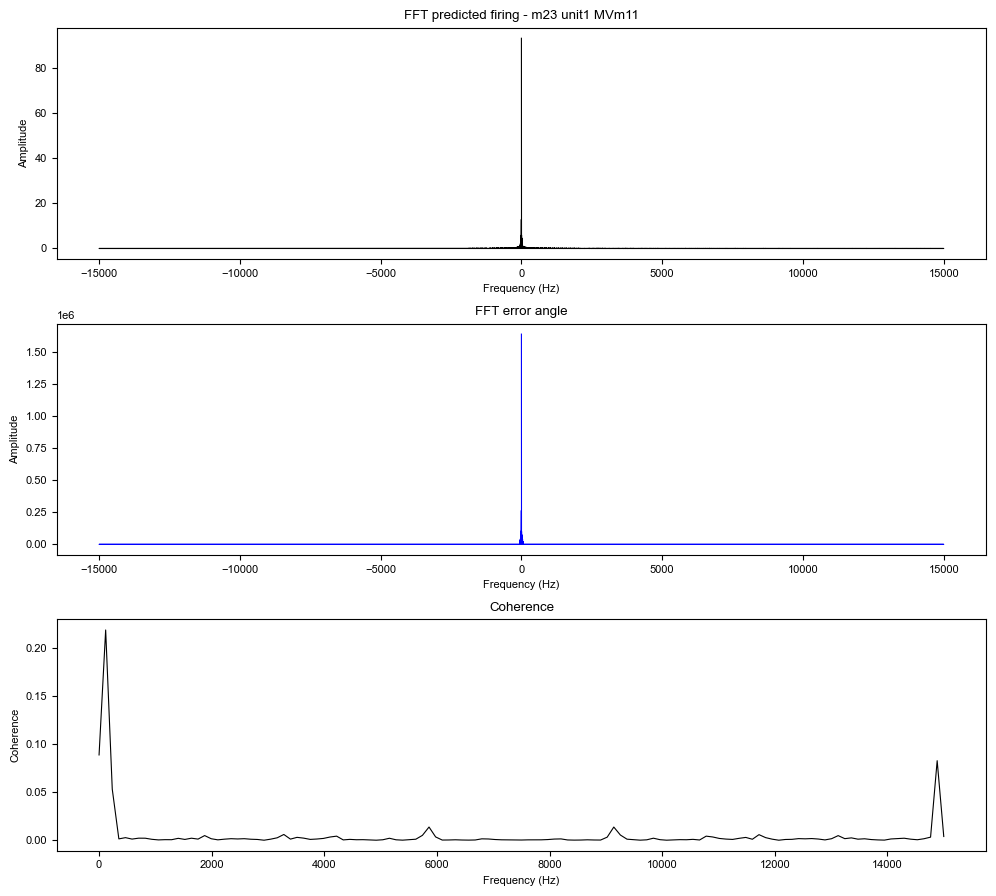

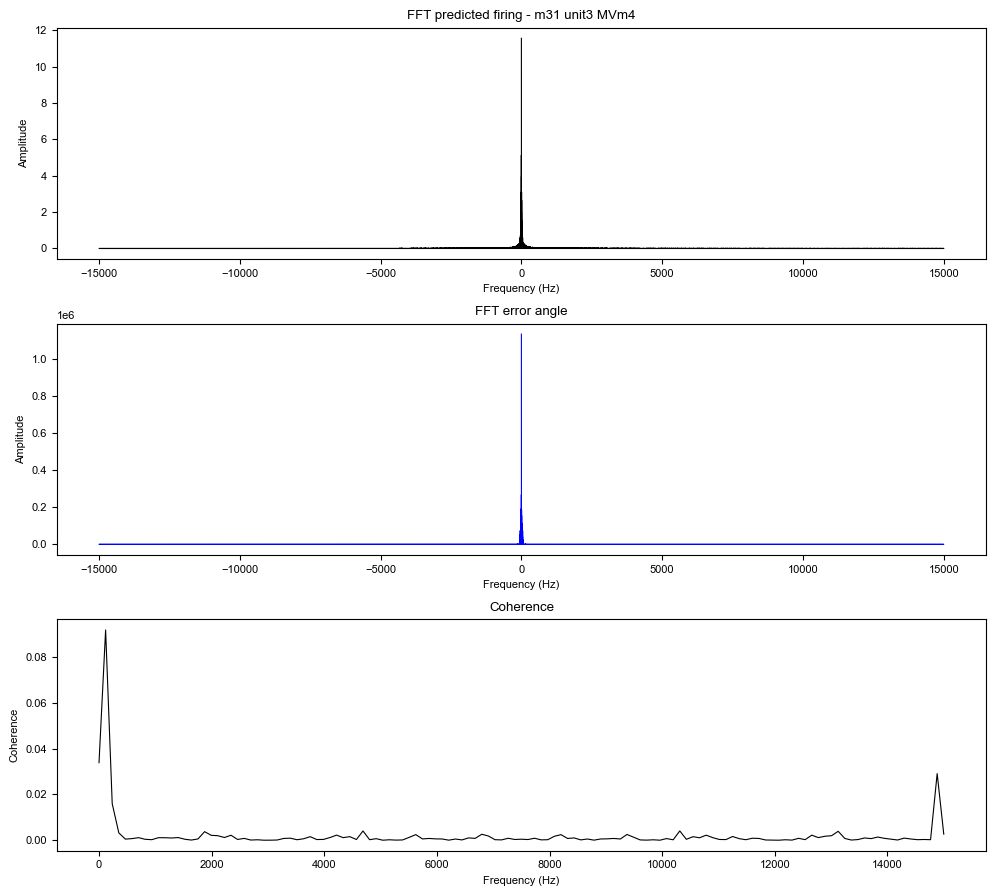

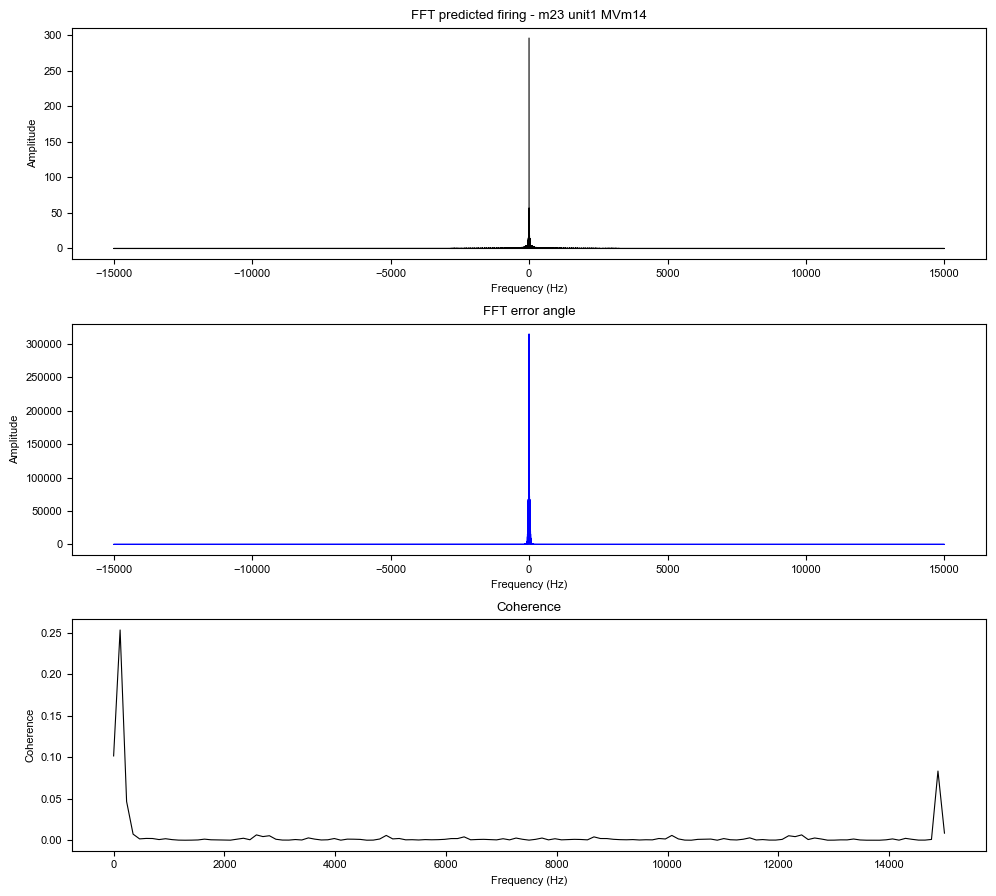

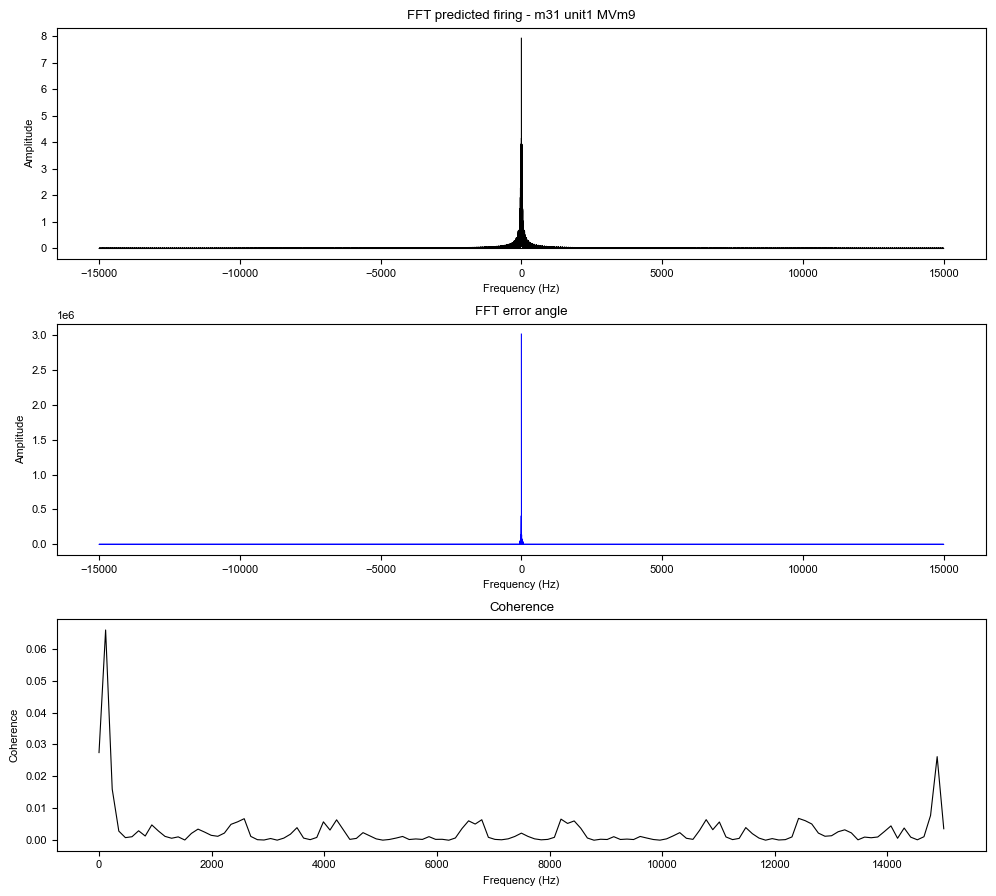

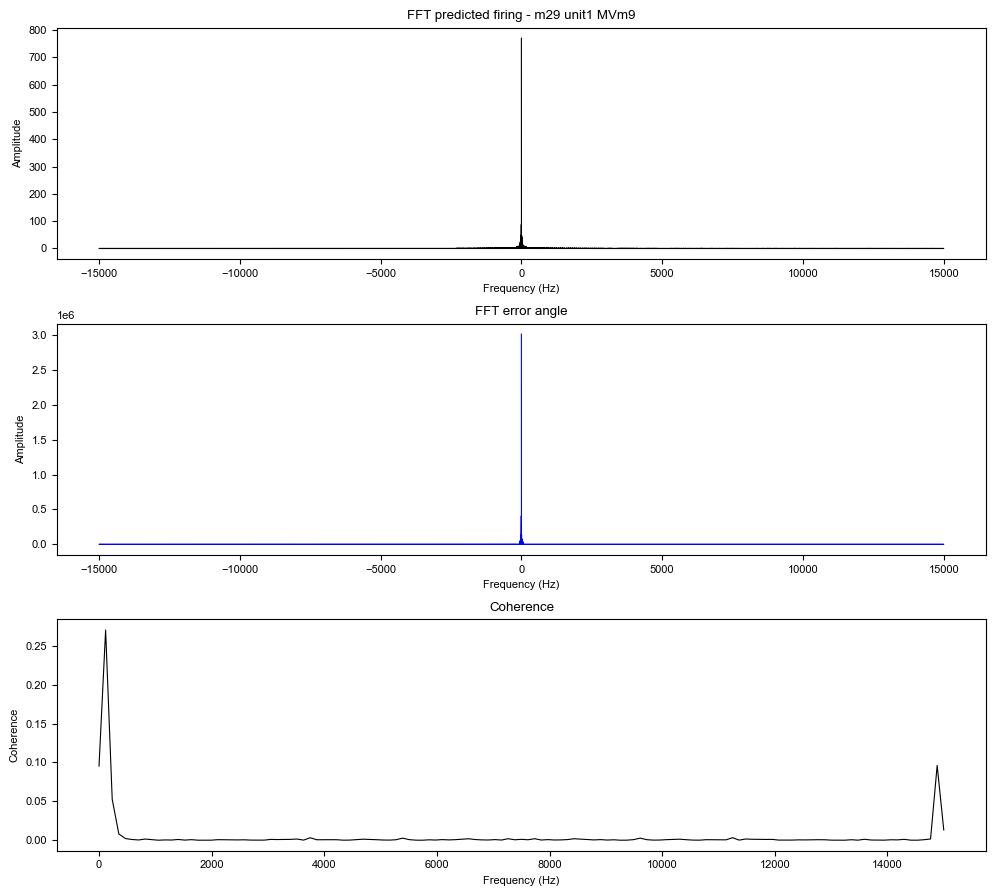

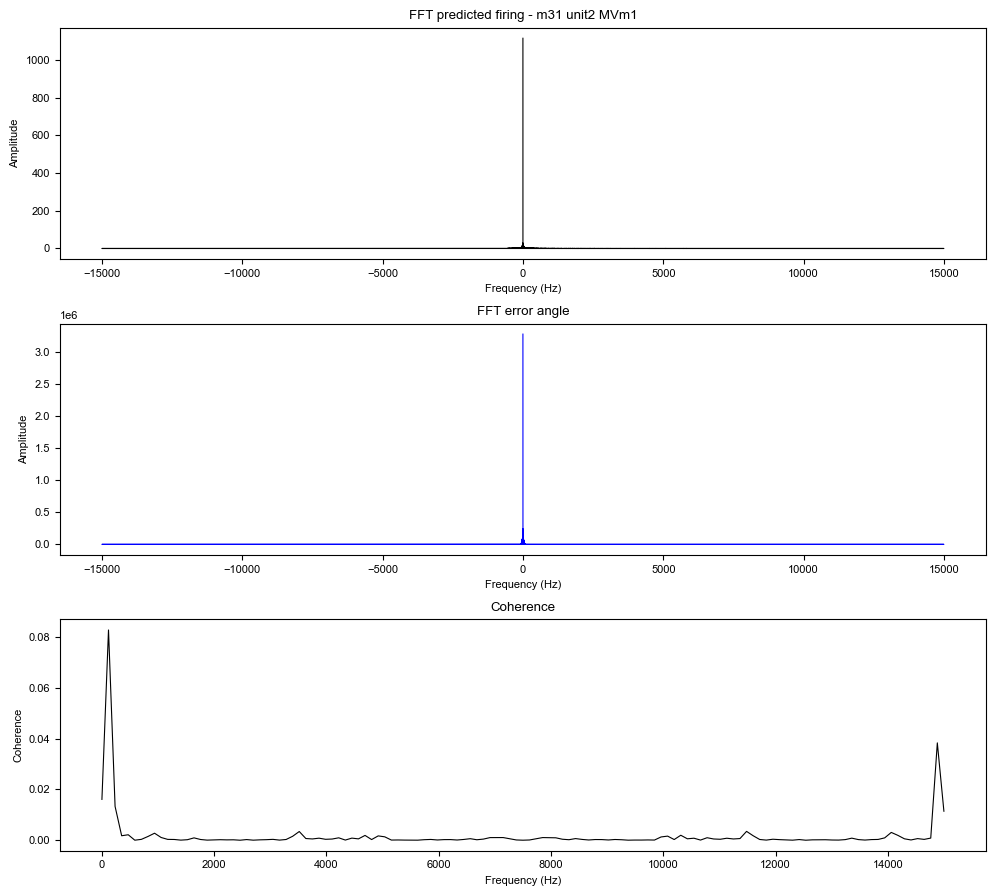

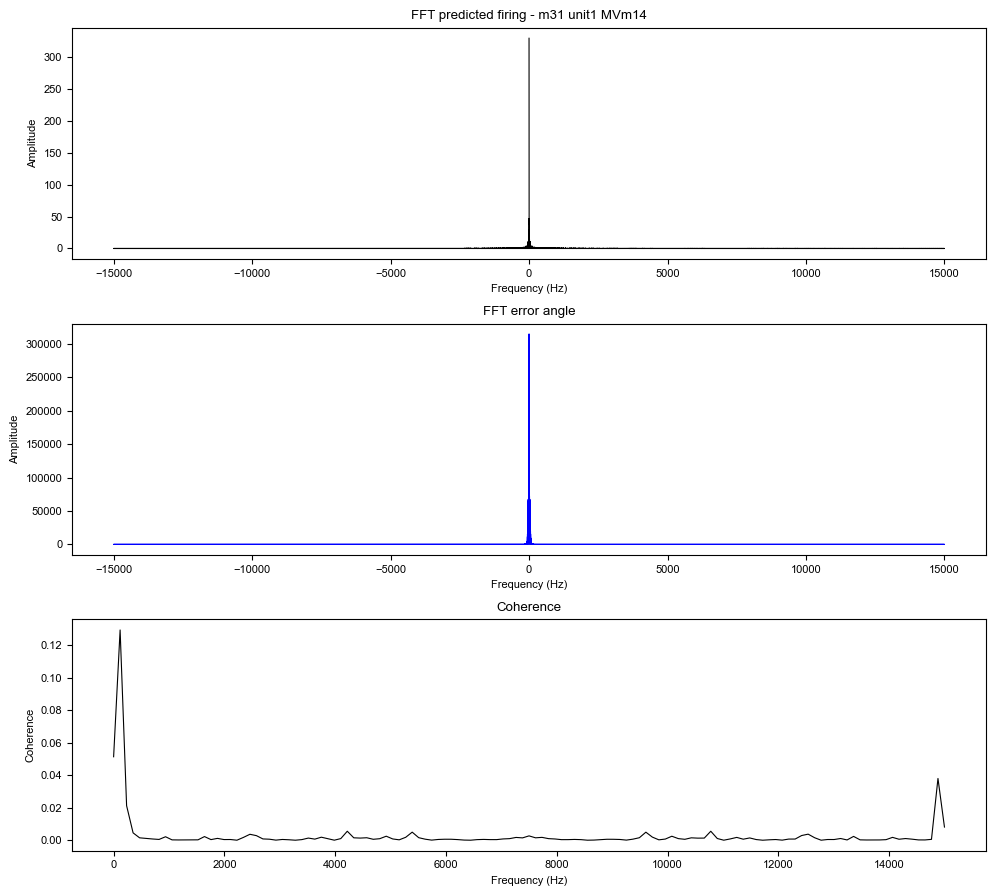

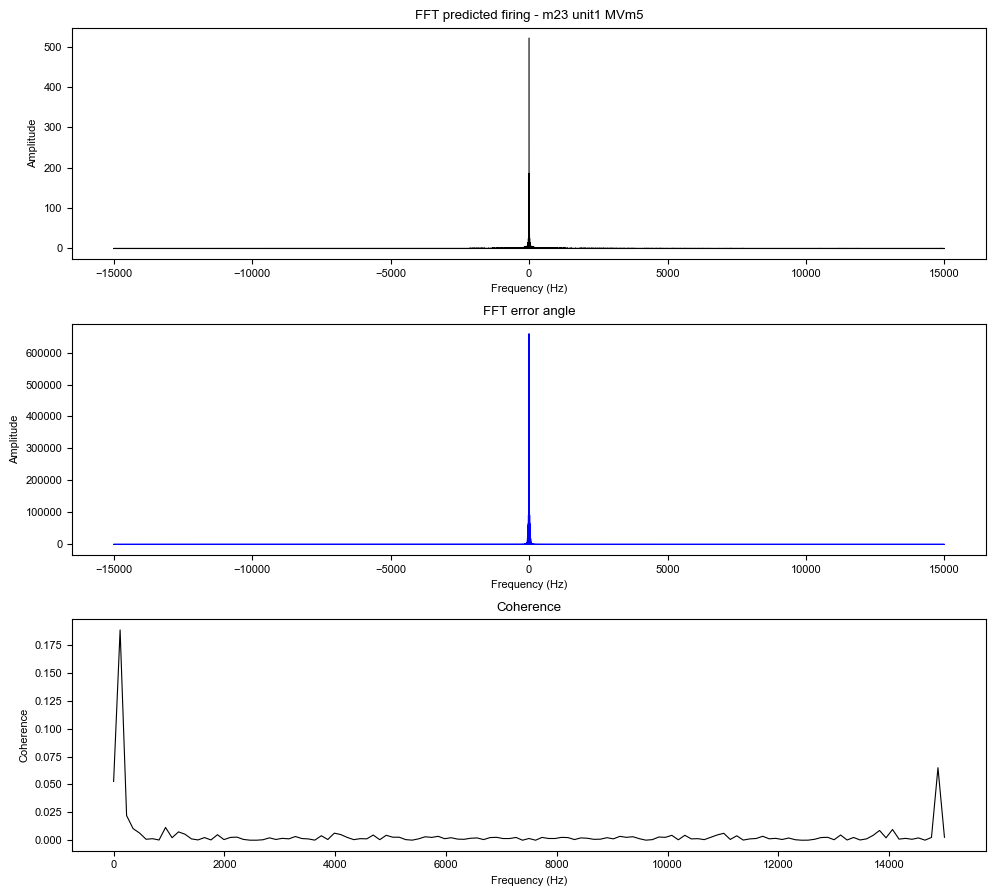

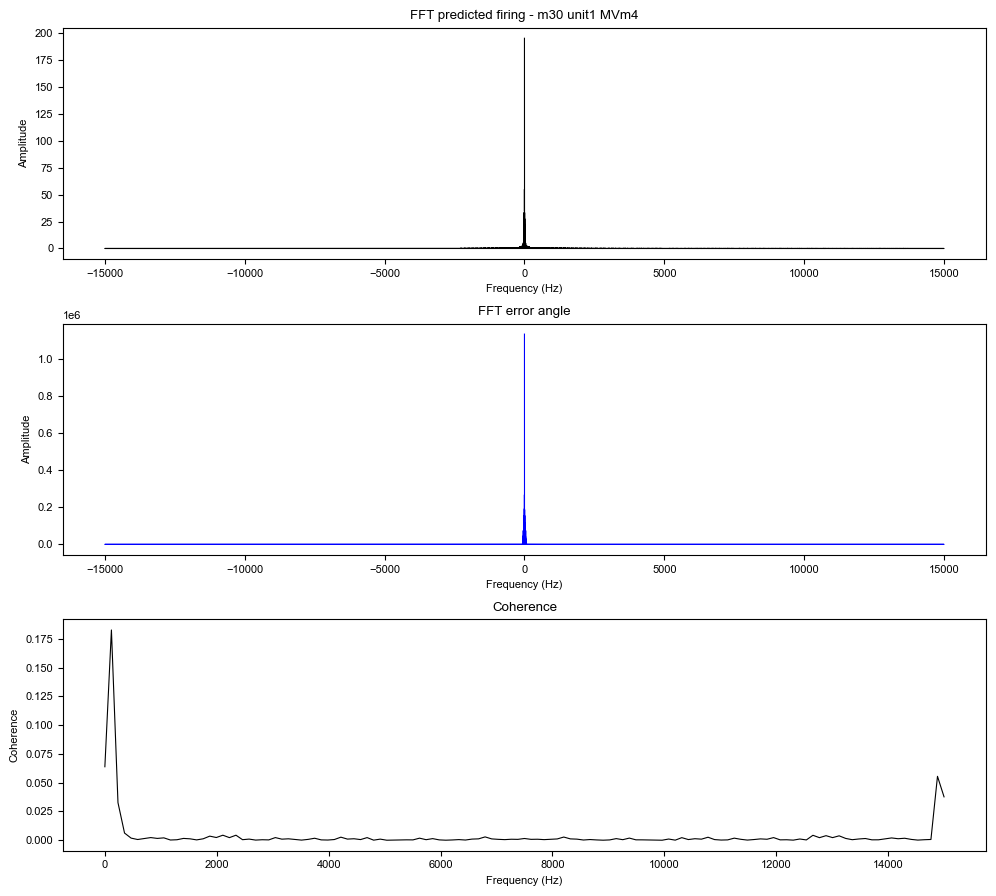

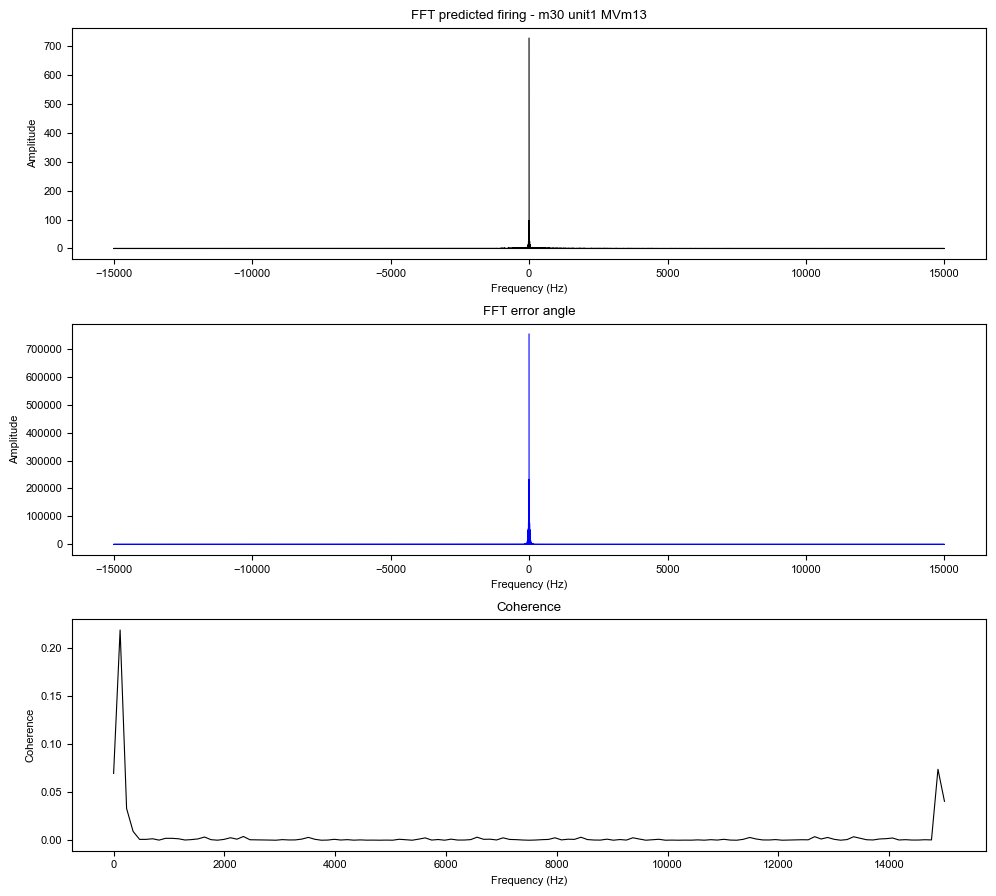

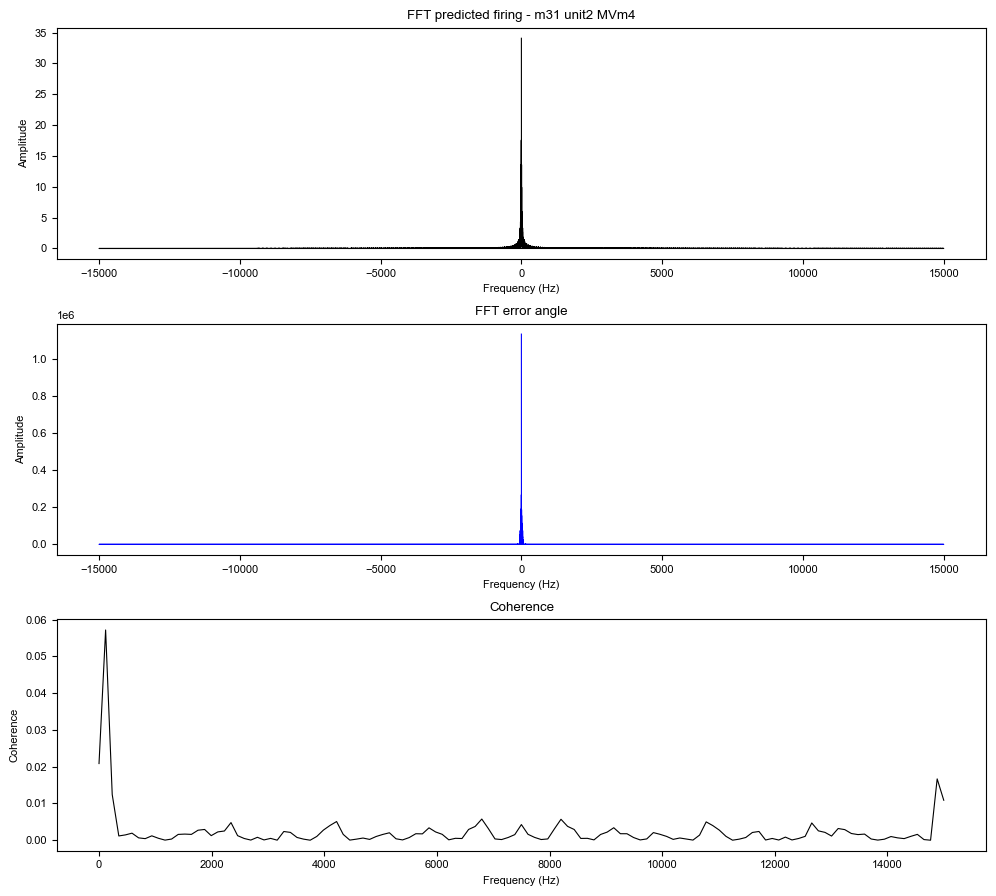

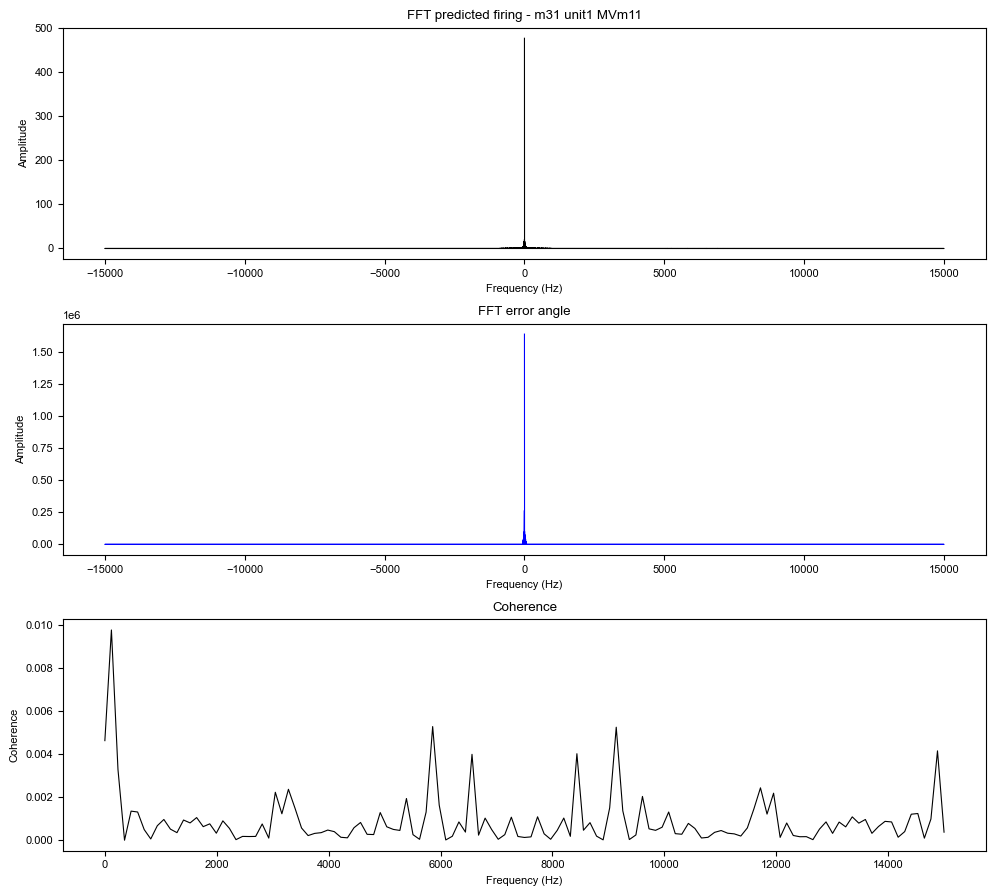

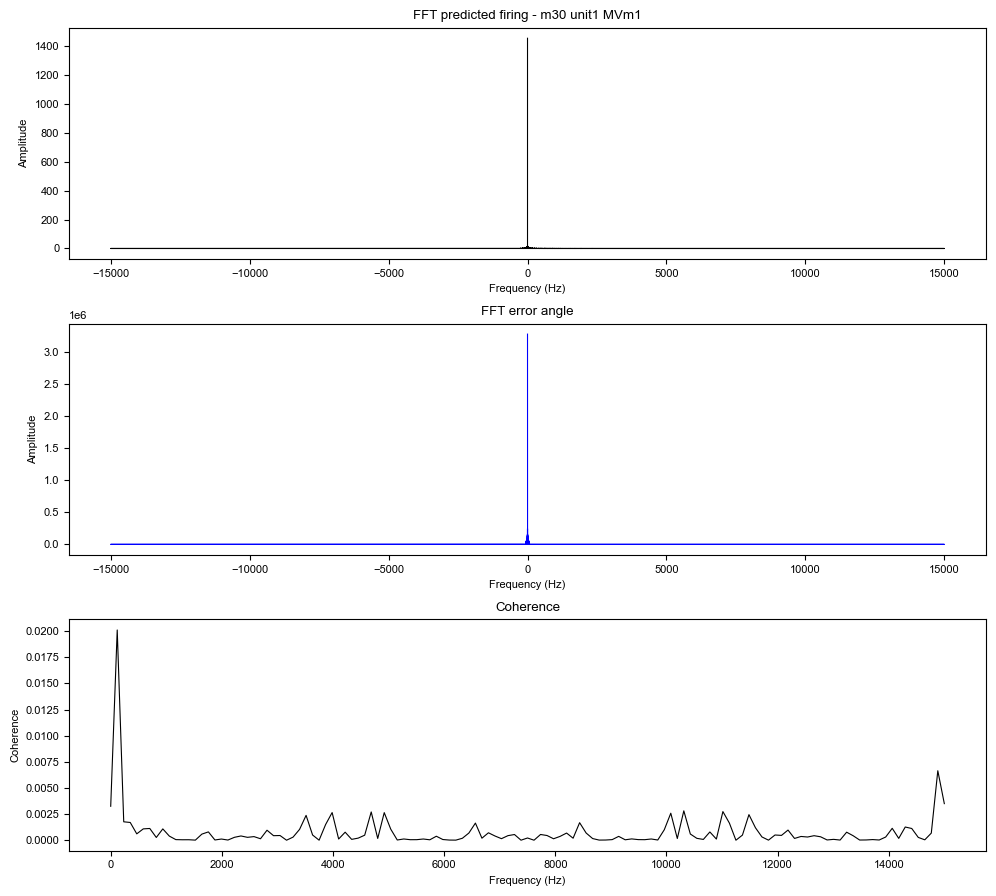

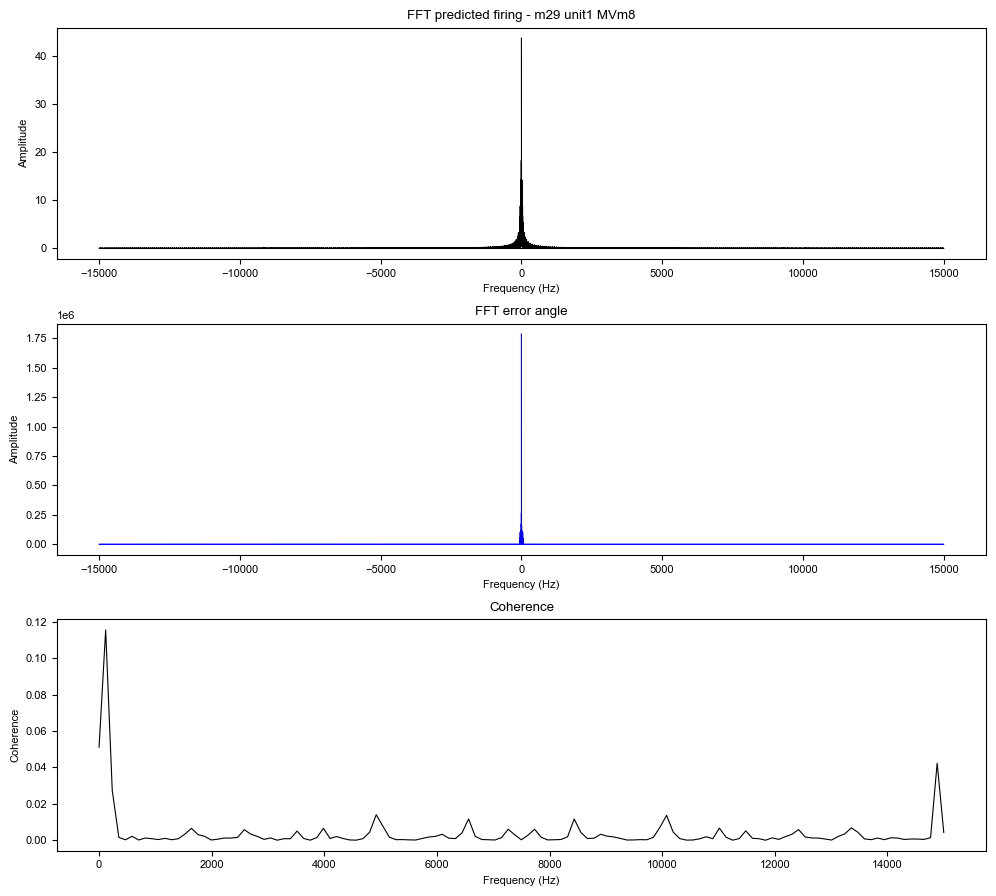

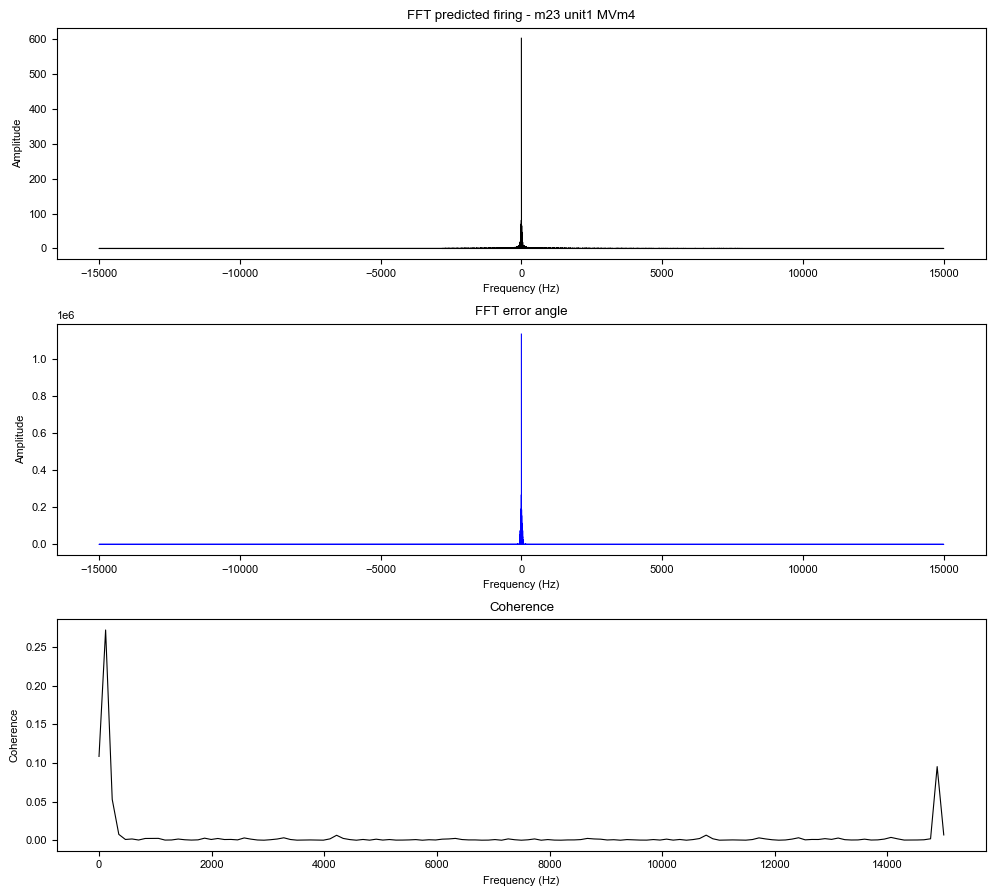

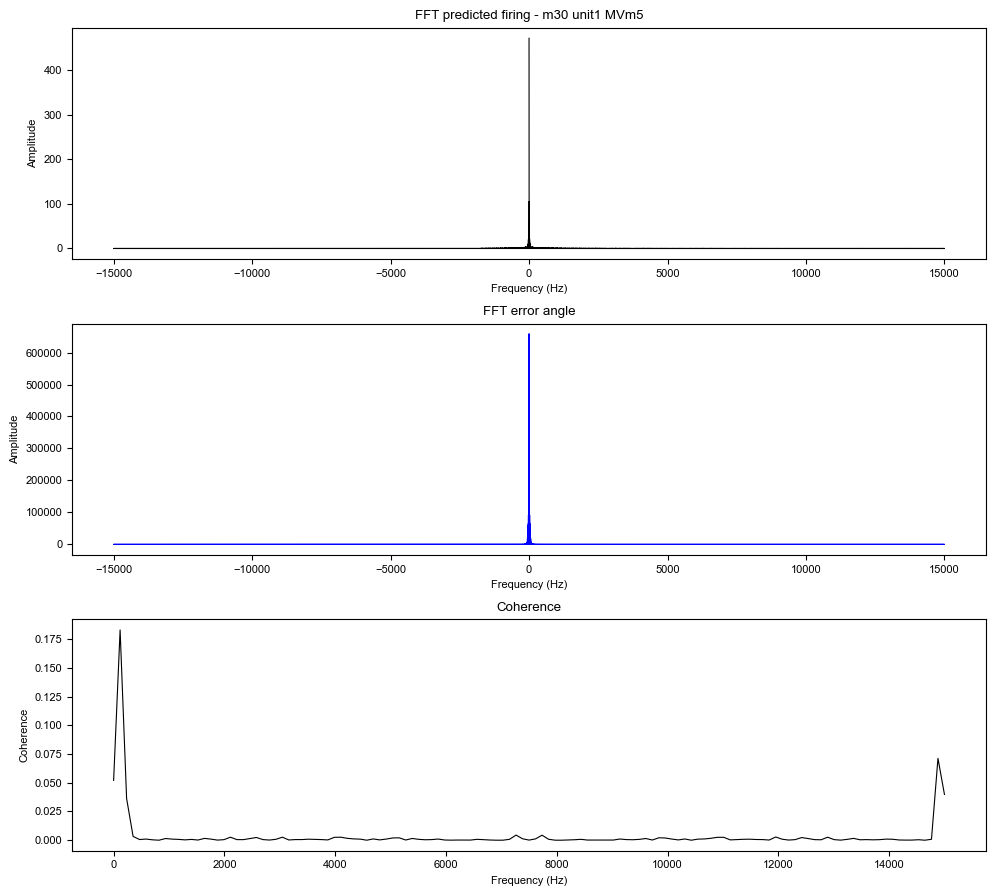

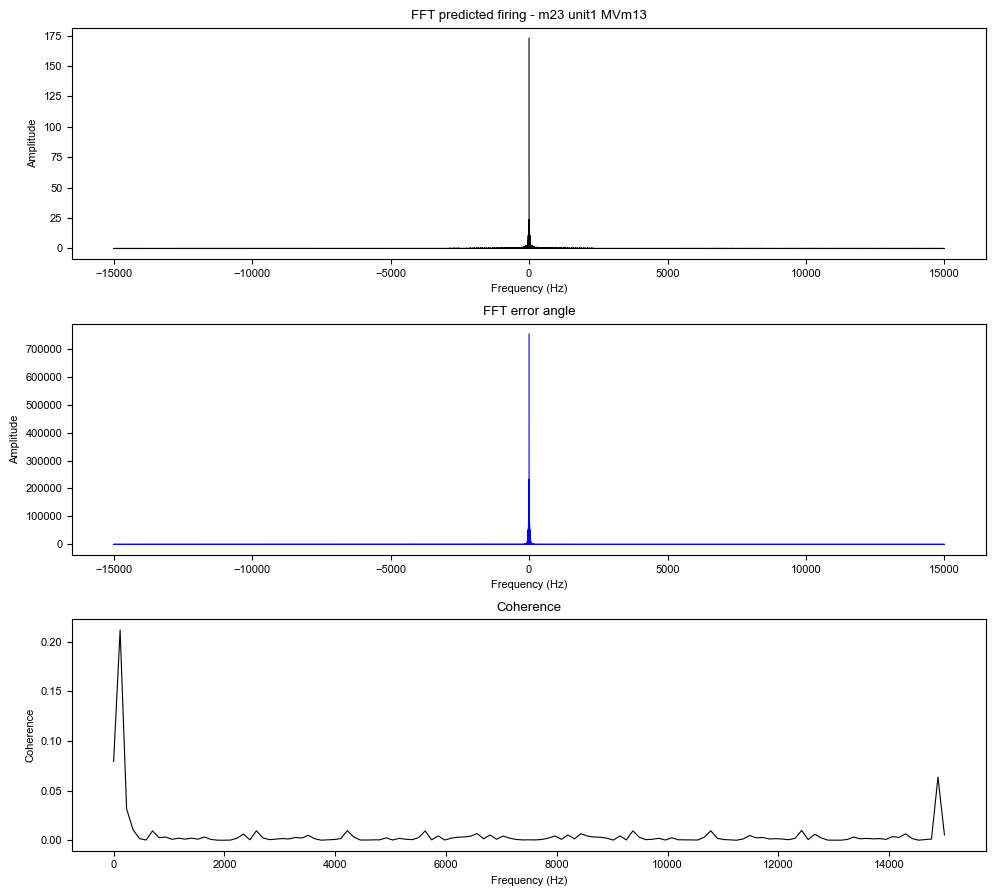

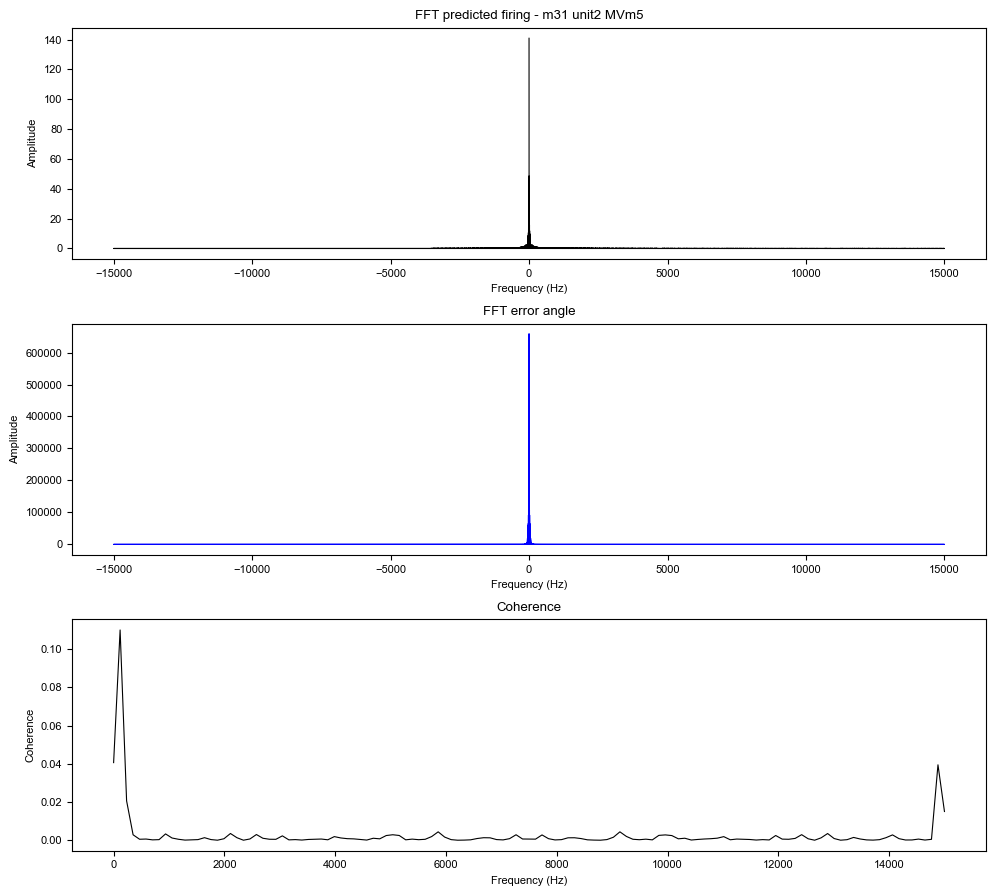

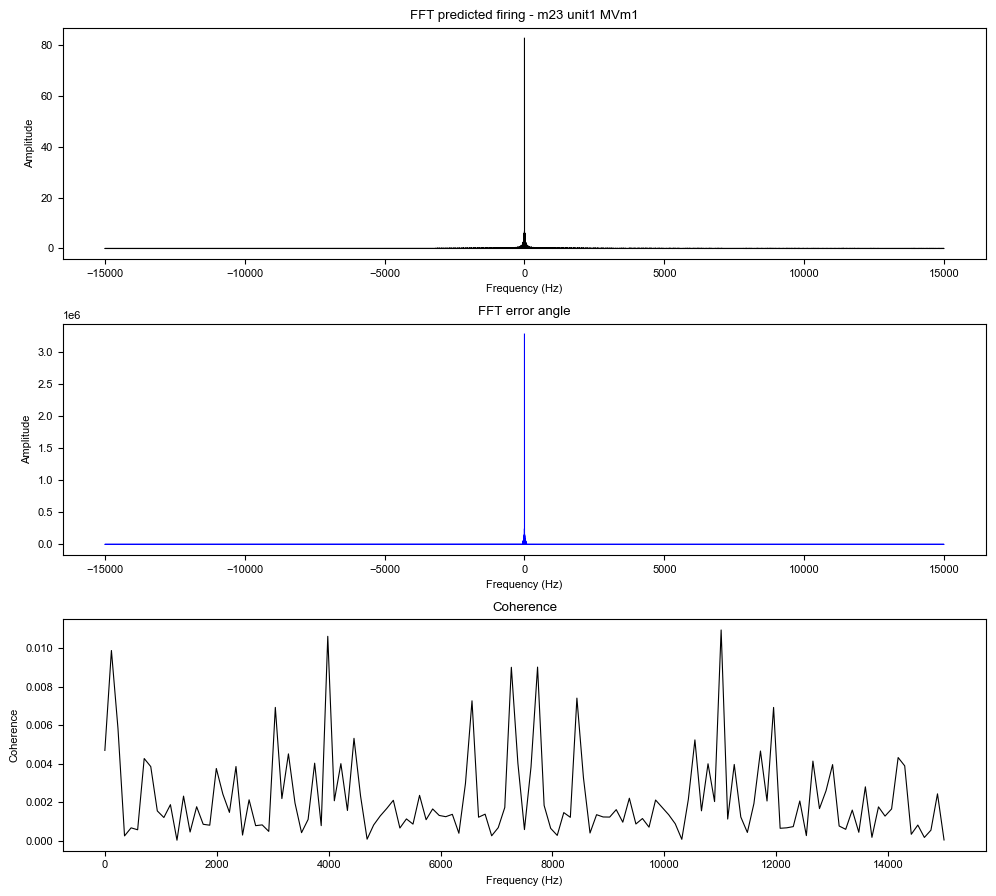

In [12]:
for filepath in glob.glob('./dataFolder/6_NaturalBehavior/Clipped_test/v2/*_Prediction.pickle'):
    with open(filepath, 'rb') as f:
        savedData = pickle.load(f)
    moth     = os.path.basename(filepath).split('_')[0]
    unitID   = os.path.basename(filepath).split('_')[1]
    vid_moth = os.path.basename(filepath).split('_')[3]

    df_proj   = savedData[2]
    upsampled = savedData[3]
    pred      = df_proj['pred_max'].values

    n     = len(pred)
    freqs = fftfreq(n, d=1/Fs)
    fft_pred      = np.abs(fft(pred))
    fft_upsampled = np.abs(fft(upsampled))

    f, Cxy = coherence(pred, upsampled, fs=Fs)

    fig, axes = plt.subplots(3, 1, figsize=(10, 9))
    axes[0].plot(freqs, fft_pred, 'k', linewidth=0.8)
    axes[0].set_title(f'FFT predicted firing - {moth} {unitID} {vid_moth}')
    axes[0].set_ylabel('Amplitude')
    axes[0].set_xlabel('Frequency (Hz)')

    axes[1].plot(freqs, fft_upsampled, 'blue', linewidth=0.8)
    axes[1].set_title('FFT error angle')
    axes[1].set_ylabel('Amplitude')
    axes[1].set_xlabel('Frequency (Hz)')

    axes[2].plot(f, Cxy, 'k', linewidth=0.8)
    axes[2].set_title('Coherence')
    axes[2].set_ylabel('Coherence')
    axes[2].set_xlabel('Frequency (Hz)')

    plt.tight_layout()
    plt.savefig(out_fig + moth + '_' + unitID + '_' + vid_moth + '_fft_coherence.pdf')
    plt.show()
    plt.close()